# **I.KIỂM TRA THÔNG TIN DỮ LIỆU**

•	Làm sạch dữ liệu: xử lý thiếu, nhiễu, ngoại lệ.

•	Chọn lọc thuộc tính (feature selection).(xử lý nâng cao)

•	Chuẩn hóa dữ liệu (nếu mô hình yêu cầu). (xử lý nâng cao)


## **I.a.KT DL cơ bản**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
df = pd.read_csv(r"C:\Users\ADMIN\Desktop\Dự án cuối kỳ-khai phá dữ liệu\filedl\bank-additional-full.csv", sep = ';')
print(df.shape)

(41188, 21)


In [2]:
#Hiện 5 dòng đầu của dữ liệu
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
#Thông tin cơ bản của dữ liệu
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [4]:
#Hiển thị tên cột (object) và các giá trị độc nhất trong nó
for col in df.columns:
    if df[col].dtype == 'object':
        print(f'\nTên của cột là: ({col}) và các giá trị độc nhất trong nó bao gồm: {df[col].unique()}')


Tên của cột là: (job) và các giá trị độc nhất trong nó bao gồm: ['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']

Tên của cột là: (marital) và các giá trị độc nhất trong nó bao gồm: ['married' 'single' 'divorced' 'unknown']

Tên của cột là: (education) và các giá trị độc nhất trong nó bao gồm: ['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']

Tên của cột là: (default) và các giá trị độc nhất trong nó bao gồm: ['no' 'unknown' 'yes']

Tên của cột là: (housing) và các giá trị độc nhất trong nó bao gồm: ['no' 'yes' 'unknown']

Tên của cột là: (loan) và các giá trị độc nhất trong nó bao gồm: ['no' 'yes' 'unknown']

Tên của cột là: (contact) và các giá trị độc nhất trong nó bao gồm: ['telephone' 'cellular']

Tên của cột là: (month) và các giá trị độc nhất trong nó bao gồm: ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr'

In [5]:
# Thống kê nhanh cho biến số
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


## **I.b.KT DL thiếu xót**

In [6]:
#Kiểm tra giá trị thiếu
print("\nCác giá trị thiếu:")
print(df.isnull().sum())


Các giá trị thiếu:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [7]:
#Kiểm tra giá trị NULL
print("\nCác giá trị NULL:")
df.isnull().sum()


Các giá trị NULL:


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [8]:
#Kiểm tra lại thông tin của bộ dữ liệu sau khi xử lý dữ liệu rác
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 


Các cột đặc trưng số:
Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')

Thống kê tóm tắt cho từng đặc trưng:
               age      duration      campaign         pdays      previous  \
count  41188.00000  41188.000000  41188.000000  41188.000000  41188.000000   
mean      40.02406    258.285010      2.567593    962.475454      0.172963   
std       10.42125    259.279249      2.770014    186.910907      0.494901   
min       17.00000      0.000000      1.000000      0.000000      0.000000   
25%       32.00000    102.000000      1.000000    999.000000      0.000000   
50%       38.00000    180.000000      2.000000    999.000000      0.000000   
75%       47.00000    319.000000      3.000000    999.000000      0.000000   
max       98.00000   4918.000000     56.000000    999.000000      7.000000   

       emp.var.rate  cons.price.idx  cons.conf.idx     euribor3m   n

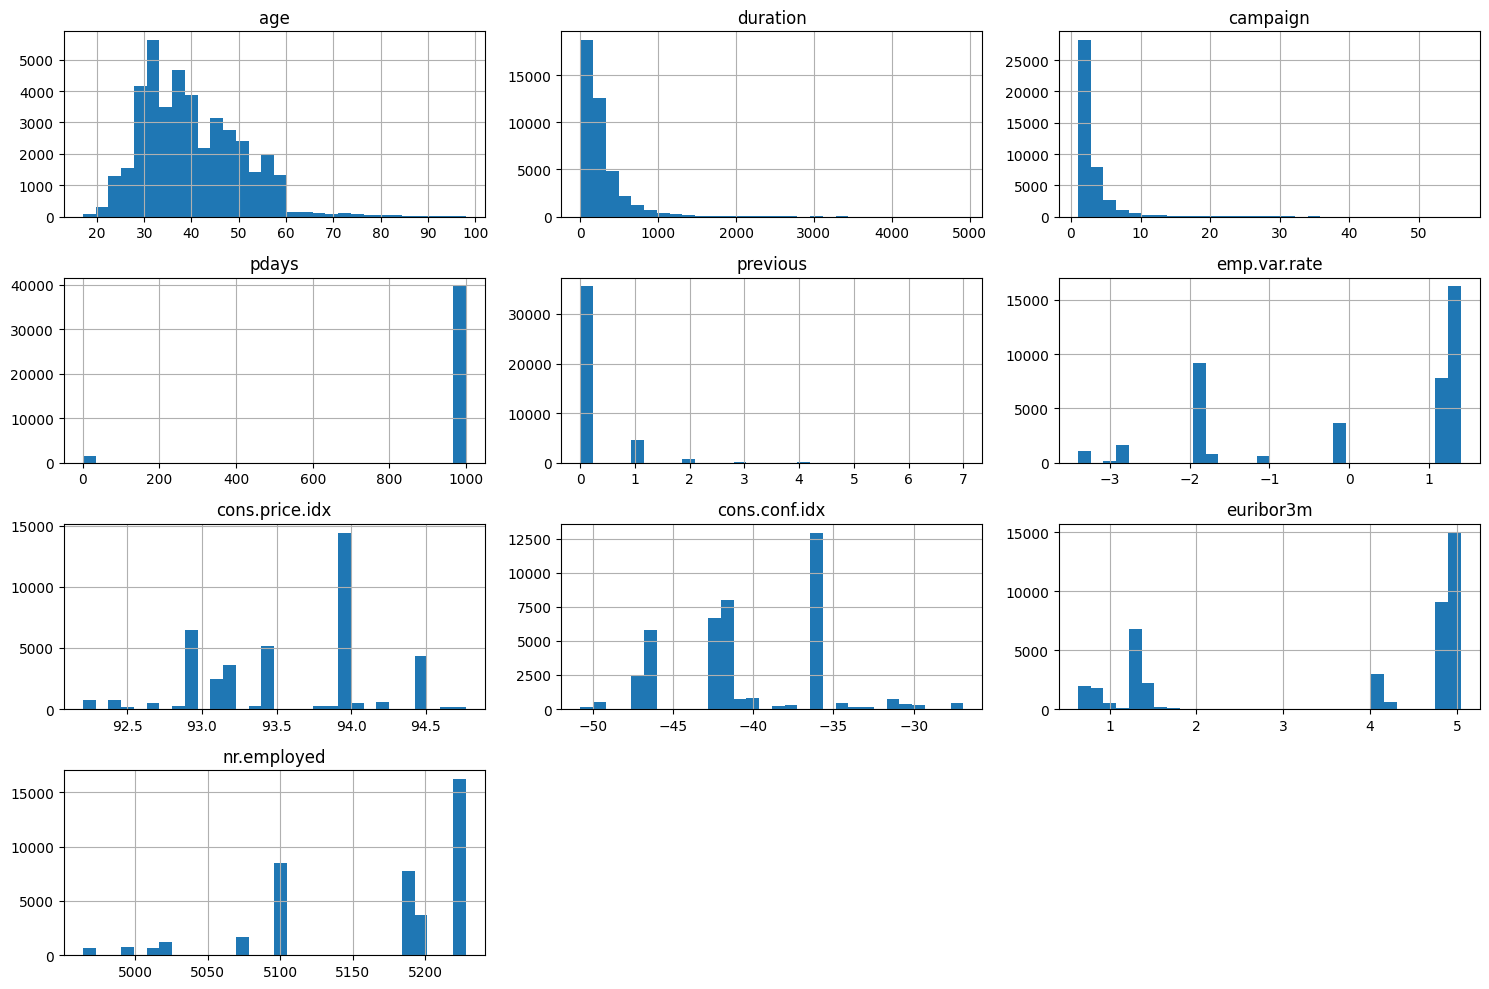


Biểu đồ hộp cho các đặc trưng để kiểm tra các giá trị ngoại lệ:


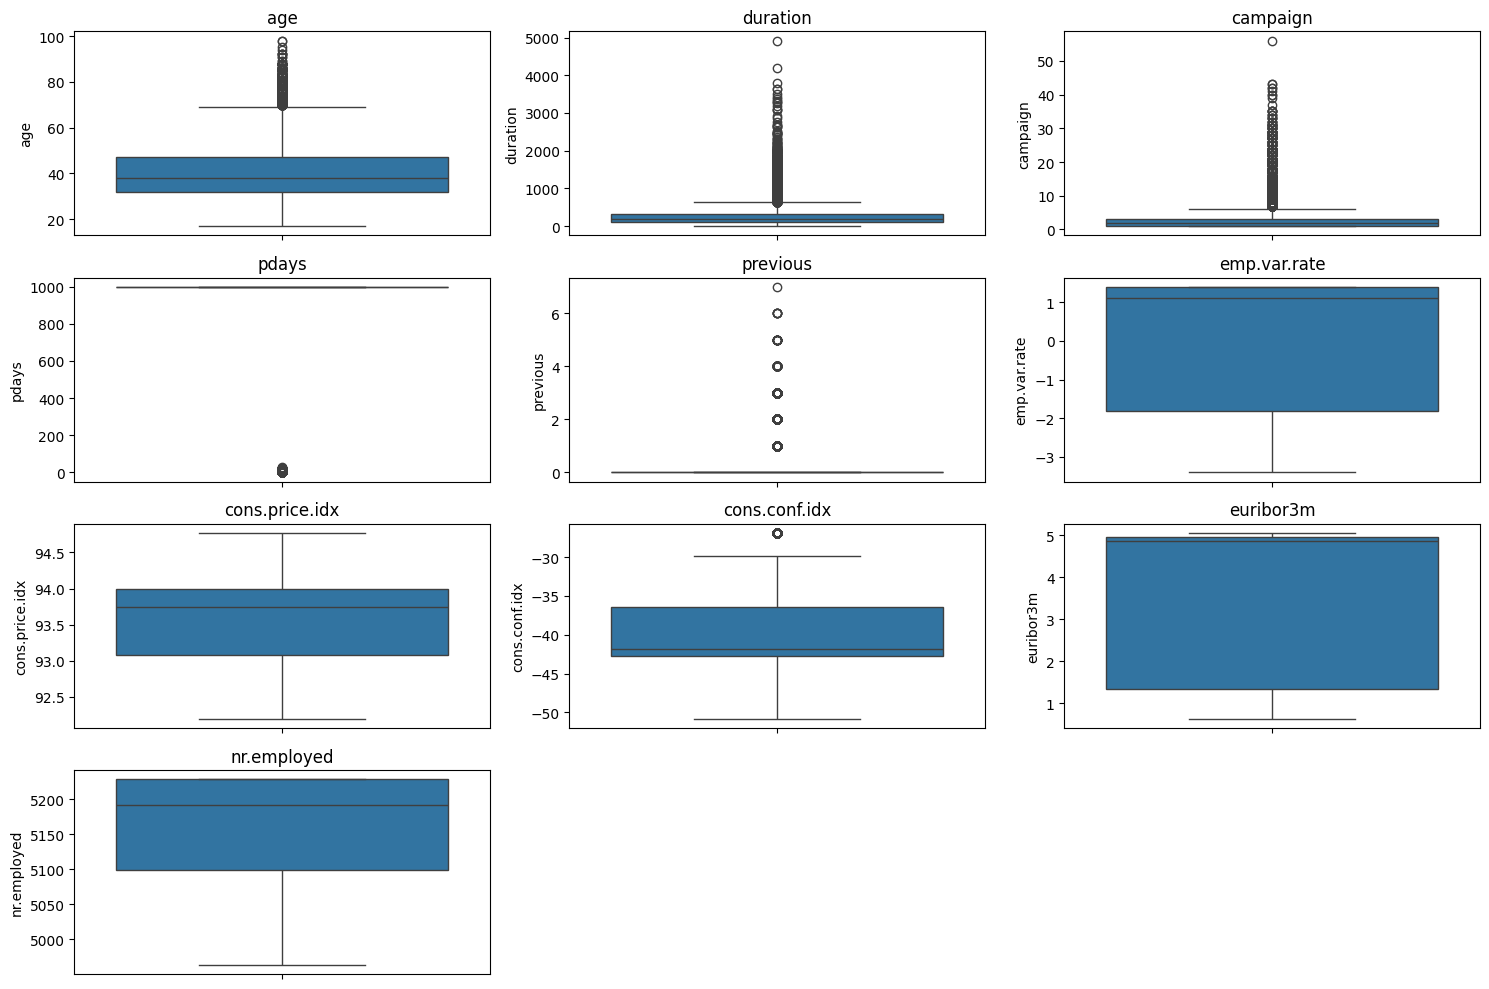

In [9]:
#Đánh giá chung cho các đặc trưng có kiểu dữ liệu là số
if df is not None:
    # Select numeric data
    numeric_data_cols = df.select_dtypes(include=np.number).columns
    print("\nCác cột đặc trưng số:")
    print(numeric_data_cols)

    # Generating summary statistics of the numerical columns
    print("\nThống kê tóm tắt cho từng đặc trưng:")
    print(df[numeric_data_cols].describe())

    # Visualizing the distribution of numerical features
    print("\nPhân bố các đặc trưng bằng biểu đồ Histogram")
    df[numeric_data_cols].hist(bins=30, figsize=(15, 10), layout=(-1, 3))
    plt.tight_layout()
    plt.show()

    print("\nBiểu đồ hộp cho các đặc trưng để kiểm tra các giá trị ngoại lệ:")
    plt.figure(figsize=(15, 10))
    for i, col in enumerate(numeric_data_cols):
        plt.subplot(4, 3, i + 1) # Adjust layout as needed
        sns.boxplot(y=df[col])
        plt.title(col)
    plt.tight_layout()
    plt.show()
else:
    print("Biểu diễn thất bại!")

**Phân tích các đặc trưng số**

- **age**: Độ tuổi của khách hàng dao động từ 17 đến 98, với tuổi trung bình khoảng 40. Phân phối có vẻ hơi lệch phải.
- **duration**: Thời lượng cuộc gọi cuối cùng có sự biến động lớn, từ 0 đến hơn 4900 giây. Trung bình rơi vào khoảng 258 giây. Đặc trưng này rất lệch phải, có nhiều cuộc gọi ngắn và một số ít cuộc gọi rất dài. Có nhiều giá trị ngoại lai ở phía trên.
- **campaign**: Số lượng liên hệ trong chiến dịch này chủ yếu là thấp (trung bình 2.5, trung vị 2), nhưng có một số khách hàng được liên hệ rất nhiều lần (tối đa 56). Phân phối lệch phải.
- **pdays**: Phần lớn giá trị là 999 (khách hàng chưa được liên hệ trước đó). Điều này làm cho việc phân tích thống kê trực tiếp (như trung bình) ít ý nghĩa nếu không xử lý giá trị 999 này riêng.
- **previous**: Số lượng liên hệ trước đó thường là 0 (trung vị 0, 75% vẫn là 0), tối đa là 7.

- **emp.var.rate**, **cons.price.idx**, **cons.conf.idx**, **euribor3m**, **nr.employed**: Các chỉ số kinh tế xã hội này có các phân phối khác nhau. `emp.var.rate` và `euribor3m` có vẻ có một số cụm giá trị. `cons.conf.idx` có phân phối khá đối xứng và tập trung. `nr.employed` có vẻ có một vài cụm giá trị.

Các biểu đồ box plot cho thấy sự hiện diện của các giá trị ngoại lai trong nhiều đặc trưng số như `age`, `duration`, `campaign`, `previous`. Đặc trưng `duration` và `campaign` có nhiều giá trị ngoại lai đáng kể.


Các cột đặc trưng phân loại:
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'y'],
      dtype='object')

Giá trị độc nhất và phân bố của chúng trong đặc trưng:

--- Cột: job ---
job
admin.           25.303486
blue-collar      22.467709
technician       16.371273
services          9.636302
management        7.099155
retired           4.175974
entrepreneur      3.535010
self-employed     3.450034
housemaid         2.573565
unemployed        2.461882
student           2.124405
unknown           0.801204
Name: proportion, dtype: float64
Số lượng giá trị độc nhất: 12

--- Cột: marital ---
marital
married     60.522482
single      28.085850
divorced    11.197436
unknown      0.194231
Name: proportion, dtype: float64
Số lượng giá trị độc nhất: 4

--- Cột: education ---
education
university.degree      29.542585
high.school            23.101389
basic.9y               14.676605
professional.course    12.729436
basic.4y 

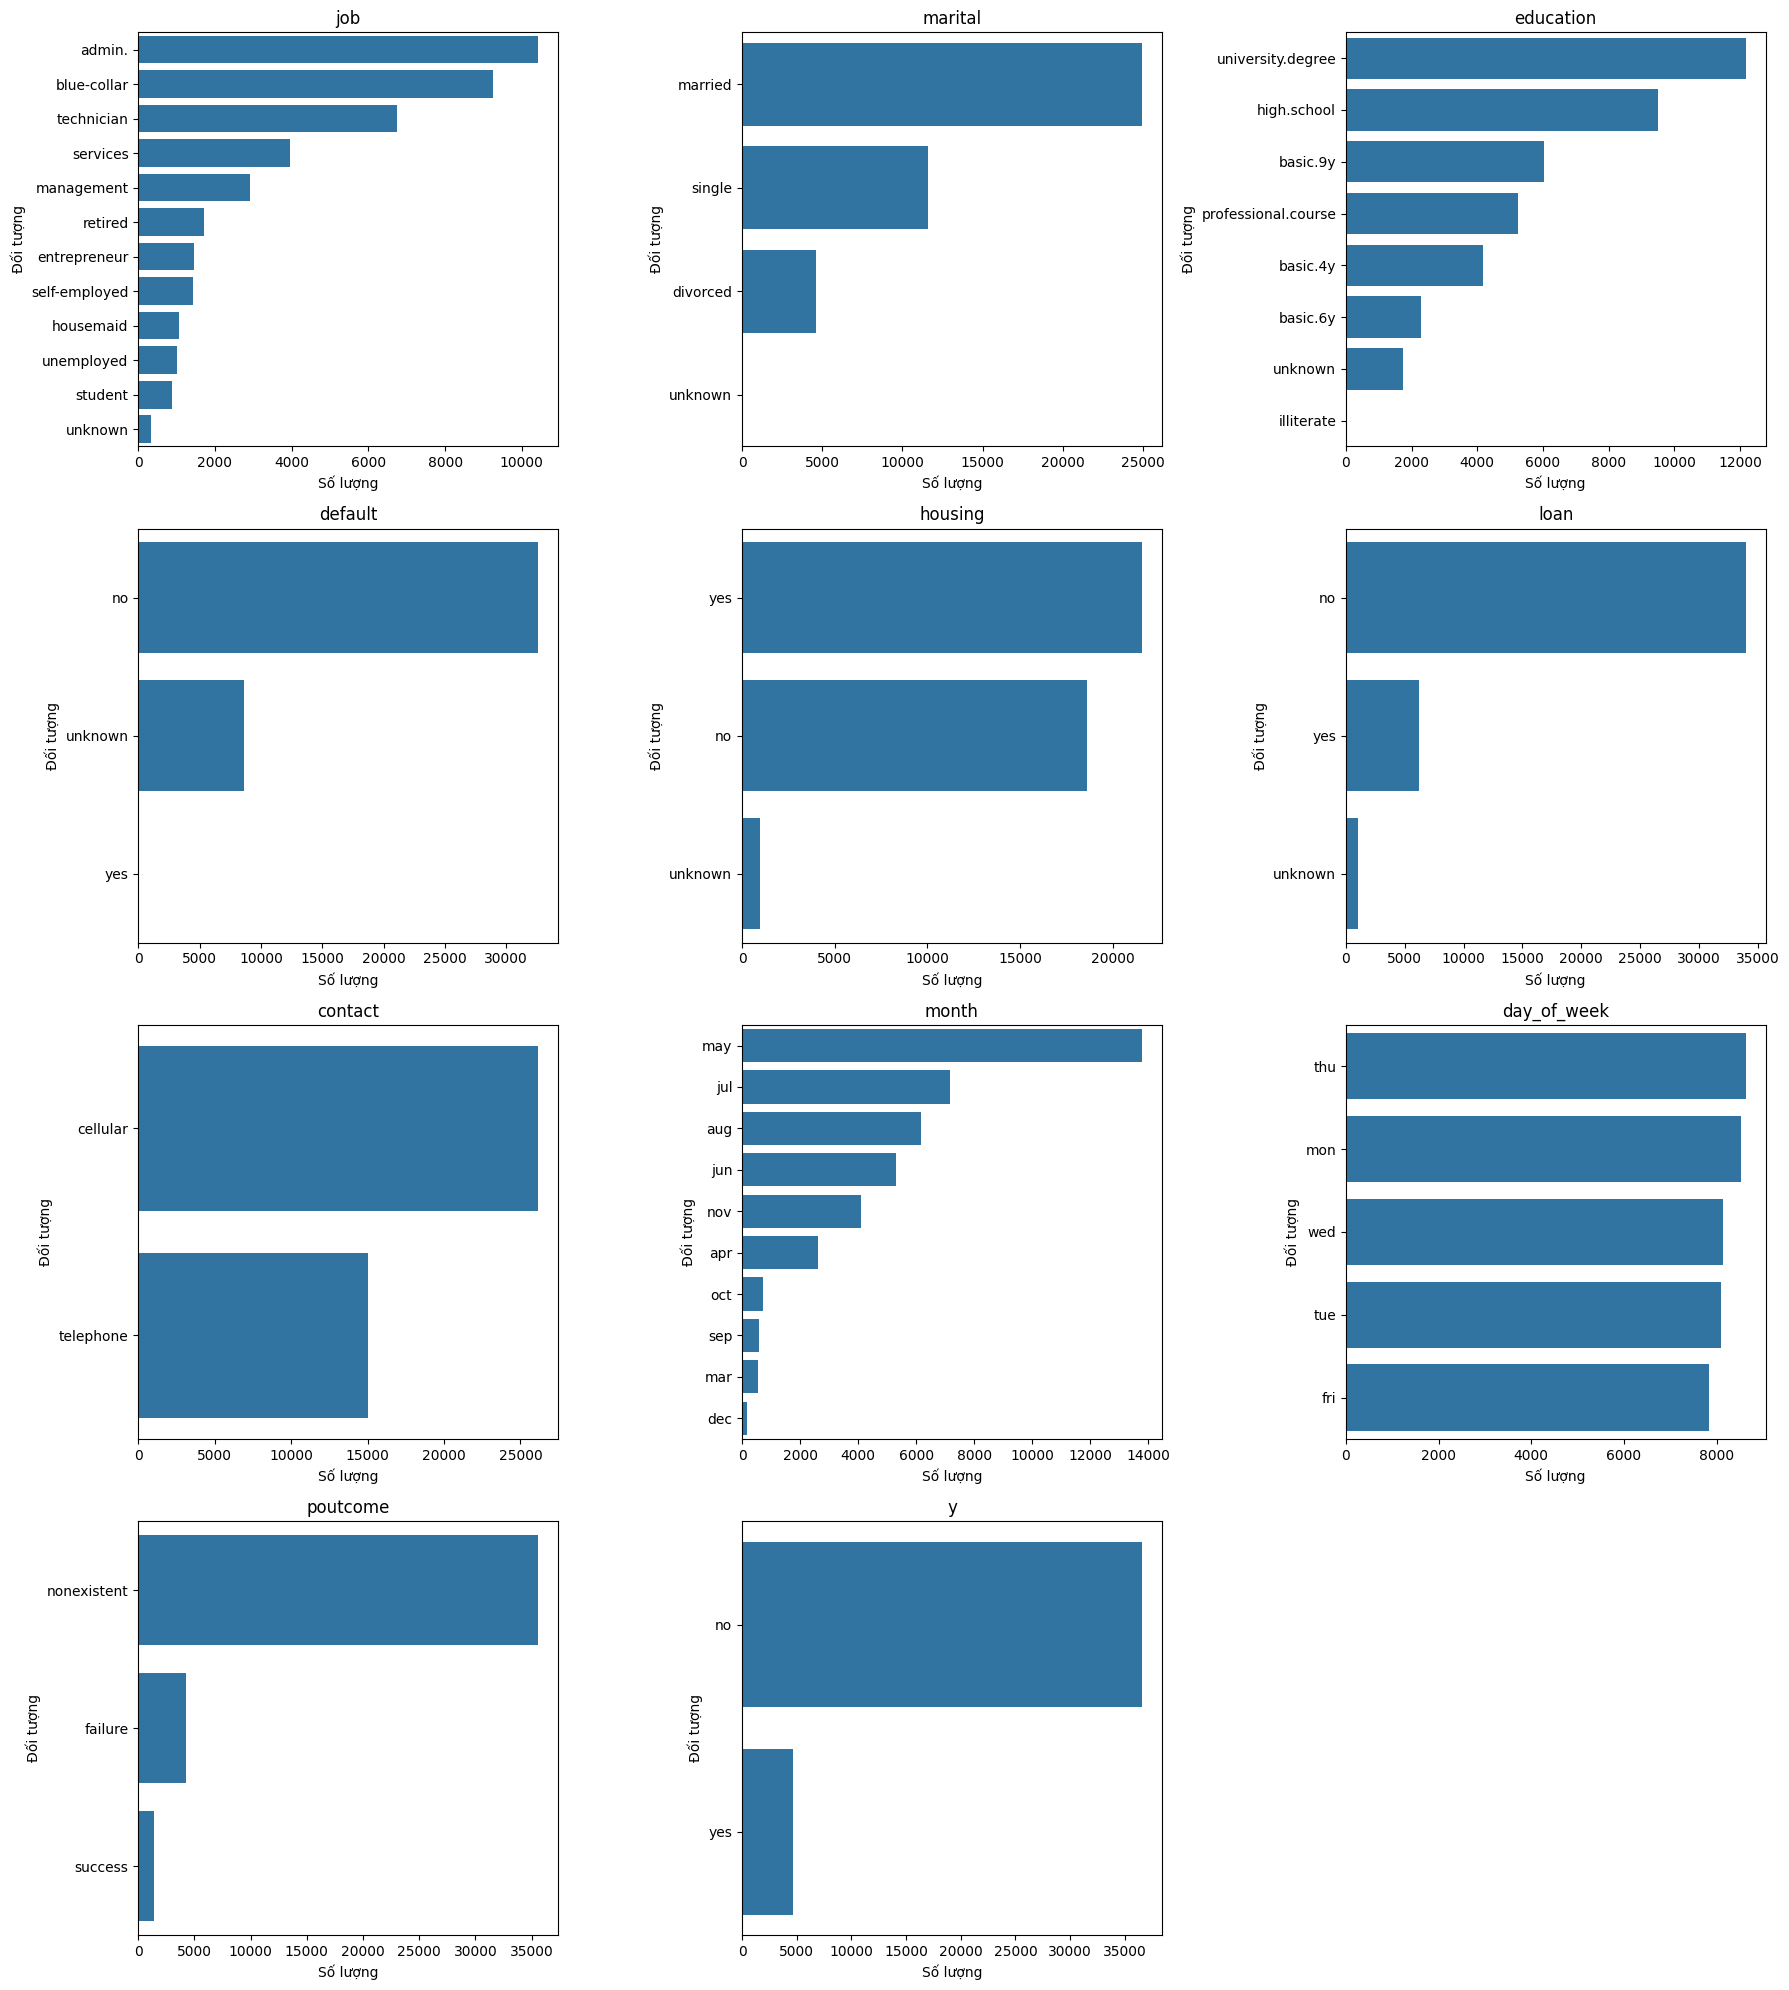


Phân phối của biến mục tiêu 'y':
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


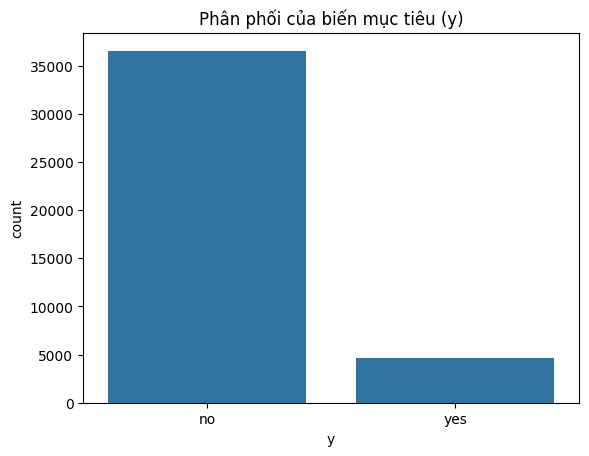

In [10]:
# Đánh giá chung cho các đặc trưng có kiểu dữ liệu là đối tượng
if df is not None:
    # Select categorical data
    categorical_data_cols = df.select_dtypes(include='object').columns
    print("\nCác cột đặc trưng phân loại:")
    print(categorical_data_cols)

    print("\nGiá trị độc nhất và phân bố của chúng trong đặc trưng:")
    for col in categorical_data_cols:
        print(f"\n--- Cột: {col} ---")
        print(df[col].value_counts(normalize=True) * 100) # Show as percentage
        print(f"Số lượng giá trị độc nhất: {df[col].nunique()}")

    # Visualizing the distribution of categorical features
    print("\nPhân phối các đặc trưng bằng biểu đồ cột\n")
    plt.figure(figsize=(18, 20)) # Adjust figure size as needed
    for i, col in enumerate(categorical_data_cols):
        plt.subplot(4, 3, i + 1)
        sns.countplot(y=df[col], order=df[col].value_counts().index)
        plt.title(col)
        plt.xlabel("Số lượng")
        plt.ylabel("Đối tượng")
    plt.tight_layout()
    plt.show()

    # Specifically, let's look at the target variable 'y'
    print("\nPhân phối của biến mục tiêu 'y':")
    print(df['y'].value_counts(normalize=True) * 100)
    sns.countplot(x='y', data=df)
    plt.title('Phân phối của biến mục tiêu (y)')
    plt.show()

else:
    print("Biểu diễn thất bại!")

**Phân tích các đặc trưng phân loại**

- **job**: `'admin.'` là công việc phổ biến nhất (khoảng 25%), tiếp theo là `'blue-collar'` (22.5%) và `'technician'` (16.3%). `'unknown'` chiếm một tỷ lệ nhỏ (0.8%).
- **marital**: `'married'` chiếm đa số (khoảng 60.5%), `'single'` (28%) và `'divorced'` (11%). `'unknown'` rất ít.
- **education**: `'university.degree'` là phổ biến nhất (29.5%), tiếp theo là `'high.school'` (23.1%) và `'basic.9y'` (14.6%). `'illiterate'` rất hiếm. Có một lượng đáng kể `'unknown'` (4.2%).
- **default**: Phần lớn khách hàng không có tín dụng mặc định (`'no'` - 79.1%). `'unknown'` chiếm tỷ lệ khá lớn (20.8%), `'yes'` rất hiếm.
- **housing**: Khoảng 52.4% có vay nhà ở (`'yes'`), 45.2% không có (`'no'`), và một phần nhỏ `'unknown'` (2.4%).
- **loan**: Phần lớn không có vay cá nhân (`'no'` - 82.4%). `'yes'` chiếm 15.2%, `'unknown'` (2.4%).
- **contact**: `'cellular'` là phương thức liên lạc chính (63.5%), còn lại là `'telephone'` (36.5%).
- **month**: Các tháng liên hệ nhiều nhất là `'may'` (33.4%), `'jul'` (17.4%), `'aug'` (15%), `'jun'` (12.9%), `'nov'` (10%).
- **day_of_week**: Phân bố khá đều qua các ngày trong tuần làm việc.
- **poutcome**: `'nonexistent'` chiếm phần lớn (86.3%), có nghĩa là hầu hết khách hàng chưa được liên hệ trong chiến dịch trước hoặc kết quả không thành công. `'failure`' (10.3%), `'success'` (3.3%).

- **y (Target variable)**: Bộ dữ liệu mất cân bằng. Khoảng 88.7% khách hàng không đăng ký (`'no'`) và chỉ 11.3% đăng ký (`'yes'`). Điều này cần được lưu ý khi xây dựng và đánh giá mô hình.

## **I.c.Xử lý dữ liệu cơ bản sau khi đọc dữ liệu**

- Duration

- Unknow

- 999

- Hàng trung lặp

**Hàng trùng lặp**

**duration**

In [11]:
df = df.drop(columns=['duration'], axis=1)

**999**

In [12]:
# Đếm số lượng giá trị 999
count_999 = (df['pdays'] == 999).sum()
print(f"Tổng số giá trị 999 trong cột pdays: {count_999}")

# Tính tỷ lệ phần trăm (tuỳ chọn thêm để dễ đánh giá)
percentage_999 = (count_999 / len(df)) * 100
print(f"Tỷ lệ chiếm: {percentage_999:.2f}% tổng dữ liệu")

Tổng số giá trị 999 trong cột pdays: 39673
Tỷ lệ chiếm: 96.32% tổng dữ liệu


In [13]:

# 1. Tạo cột nhị phân: đã từng được liên hệ trước hay chưa
df['has_prev_contact'] = (df['pdays'] != 999).astype(int)

# 2. Tạo cột số ngày "sạch": 999 -> 0, các giá trị khác giữ nguyên
df['pdays_clean'] = df['pdays'].replace(999, 0)

# 3. Xoá cột pdays gốc (không còn giá trị vì đã tách thông tin)
df.drop(columns=['pdays'], inplace=True)

# 4. (Khuyến nghị) Sắp xếp lại thứ tự cột cho đẹp
df = df[['has_prev_contact', 'pdays_clean'] + 
        [col for col in df.columns if col not in ['has_prev_contact', 'pdays_clean']]]


In [14]:
df[df['has_prev_contact'] == 0]


,has_prev_contact,pdays_clean,age,job,marital,education,default,housing,loan,contact,...,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,0,56,housemaid,married,basic.4y,no,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,0,0,57,services,married,high.school,unknown,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,0,0,37,services,married,high.school,no,yes,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,0,0,40,admin.,married,basic.6y,no,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,0,0,56,services,married,high.school,no,no,yes,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,0,0,73,retired,married,professional.course,no,yes,no,cellular,...,fri,1,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,0,0,46,blue-collar,married,professional.course,no,no,no,cellular,...,fri,1,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,0,0,56,retired,married,university.degree,no,yes,no,cellular,...,fri,2,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,0,0,44,technician,married,professional.course,no,no,no,cellular,...,fri,1,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [15]:
df[df['has_prev_contact'] == 1]


,has_prev_contact,pdays_clean,age,job,marital,education,default,housing,loan,contact,...,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
24108,1,6,37,admin.,married,university.degree,no,yes,no,telephone,...,wed,1,1,success,-0.1,93.200,-42.0,4.286,5195.8,no
24264,1,4,48,management,married,university.degree,no,yes,no,cellular,...,mon,1,1,success,-0.1,93.200,-42.0,4.191,5195.8,no
24279,1,4,42,technician,married,professional.course,unknown,yes,no,cellular,...,mon,1,1,success,-0.1,93.200,-42.0,4.191,5195.8,no
24397,1,3,50,entrepreneur,married,university.degree,unknown,yes,no,cellular,...,mon,1,1,success,-0.1,93.200,-42.0,4.191,5195.8,no
24482,1,4,36,self-employed,single,university.degree,no,yes,no,cellular,...,mon,2,1,success,-0.1,93.200,-42.0,4.191,5195.8,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41163,1,4,35,technician,divorced,basic.4y,no,yes,no,cellular,...,tue,3,2,success,-1.1,94.767,-50.8,1.035,4963.6,yes
41164,1,10,54,admin.,married,professional.course,no,no,no,cellular,...,tue,2,1,success,-1.1,94.767,-50.8,1.035,4963.6,yes
41174,1,1,62,retired,married,university.degree,no,yes,no,cellular,...,thu,1,6,success,-1.1,94.767,-50.8,1.031,4963.6,yes
41178,1,6,62,retired,married,university.degree,no,no,no,cellular,...,thu,2,3,success,-1.1,94.767,-50.8,1.031,4963.6,yes


**Unknow**

In [16]:
# Tính tổng số dòng
total_rows = len(df)

print(f"Tổng số dòng: {total_rows}\n")
print("Thống kê giá trị 'unknown' trong từng cột:")
print("-" * 60)
print(f"{'Tên cột':<20} | {'Số lượng unknown':<20} | {'Tỷ lệ (%)':<10}")
print("-" * 60)

# Duyệt qua từng cột để đếm
for col in df.columns:
    # Kiểm tra xem cột có phải kiểu dữ liệu object (chuỗi) hay không, vì 'unknown' thường là chuỗi
    if df[col].dtype == 'object':
        unknown_count = (df[col] == 'unknown').sum()
        if unknown_count > 0:
            percentage = (unknown_count / total_rows) * 100
            print(f"{col:<20} | {unknown_count:<20} | {percentage:.2f}%")

Tổng số dòng: 41188

Thống kê giá trị 'unknown' trong từng cột:
------------------------------------------------------------
Tên cột              | Số lượng unknown     | Tỷ lệ (%) 
------------------------------------------------------------
job                  | 330                  | 0.80%
marital              | 80                   | 0.19%
education            | 1731                 | 4.20%
default              | 8597                 | 20.87%
housing              | 990                  | 2.40%
loan                 | 990                  | 2.40%


**encode yes và no trong y (xử lý ở bước này cũng được)**

In [17]:
if 'y' in df.columns:
    df['y_encoded'] = df['y'].map({'yes': 1, 'no': 0})
    df = df.drop('y', axis=1)
    print("-> Đã mã hóa biến mục tiêu 'y' thành 'y_encoded' (1: yes, 0: no).")
else:
    print("-> Biến mục tiêu 'y' đã được mã hóa hoặc không tồn tại.")

-> Đã mã hóa biến mục tiêu 'y' thành 'y_encoded' (1: yes, 0: no).


1. Xử lý các giá trị unknown

    Trong bộ dữ liệu có nhiều biến dạng phân loại như job, marital, education, default, housing, loan… và một số trong đó chứa giá trị "unknown".
    Cách xử lý như sau:

    Cách xử lý

        Giữ nguyên "unknown" như một category riêng.

    Lý do:

        "Unknown" thường chứa thông tin thực về việc khách hàng từ chối trả lời → mang ý nghĩa hành vi.

        Các mô hình như Decision Tree, Random Forest, XGBoost xử lý category “unknown” tốt.

        Logistic Regression và KNN cũng không bị ảnh hưởng sau khi One-Hot Encoding.

    Kết luận

        Giữ “unknown” và encode như các giá trị khác.
        Không xoá dòng, không fill bằng mode vì sẽ làm sai lệch dữ liệu.
        Nhưng sẽ được xem xét lại trong xử lý nâng cao

    **Lưu ý: sẽ thực hiện ở bước xử lý nâng cao sau eda**

2. Xử lý giá trị 999 trong pdays

    Trong bộ dữ liệu, biến pdays có:

        Giá trị 999 chiếm ~96% tổng số dòng → thể hiện khách hàng chưa từng được liên hệ trước đó.

    Vấn đề

        Giá trị 999 không phải số thật, gây nhiễu khi:

            Scaling

            Xây mô hình tuyến tính

            Phân cụm K-Means

            Tính khoảng cách

    Mục tiêu xử lý

        Tách bạch thông tin quan trọng:

            - Khách hàng đã từng được liên hệ / chưa từng.

            - Số ngày kể từ lần liên hệ cuối (với những người đã được gọi).

    Cách xử lý chuẩn

        Tạo 2 biến mới thay cho pdays gốc:

            df['has_prev_contact'] = (df['pdays'] != 999).astype(int)
            df['pdays_clean'] = df['pdays'].replace(999, 0)

    Ý nghĩa:

        has_prev_contact

            1 = đã từng được liên hệ

            0 = chưa từng

        pdays_clean

            Với người chưa được liên hệ → 0

            Với người đã được liên hệ → giữ nguyên số ngày thật

    Sau đó có thể xoá cột gốc pdays:
        df = df.drop(columns=['pdays'])

    Lý do xoá:

        Tránh trùng thông tin với 2 đặc trưng mới.

        Tránh đưa giá trị 999 vào mô hình → méo kết quả.

3. Duration: Gây data leaked -> xoá luôn, vì chỉ khi khách hàng đã được gọi thì mới có duration

In [18]:
df.head()

,has_prev_contact,pdays_clean,age,job,marital,education,default,housing,loan,contact,...,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y_encoded
0,0,0,56,housemaid,married,basic.4y,no,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,0,0,57,services,married,high.school,unknown,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,0,0,37,services,married,high.school,no,yes,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,0,0,40,admin.,married,basic.6y,no,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,0,0,56,services,married,high.school,no,no,yes,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


# **III.EDA**

•	Thống kê cơ bản.

•	Biểu đồ: histogram, boxplot, scatter, heatmap correlation.

•	Nhận xét và rút ra insight.




In [19]:
# 1. Lấy toàn bộ cột dạng numeric (tự động)
cont_vars = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Các biến liên tục phát hiện được:")
print(cont_vars)

Các biến liên tục phát hiện được:
['has_prev_contact', 'pdays_clean', 'age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y_encoded']


In [20]:
cat_vars = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Các biến phân loại phát hiện được:")
print(cat_vars)

Các biến phân loại phát hiện được:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [21]:
target = 'y_encoded'

## **III.a.Thiết lập tk cơ bản**
> Bước này đáp ứng yêu cầu "Thống kê cơ bản (mean, median, distribution, correlation)".

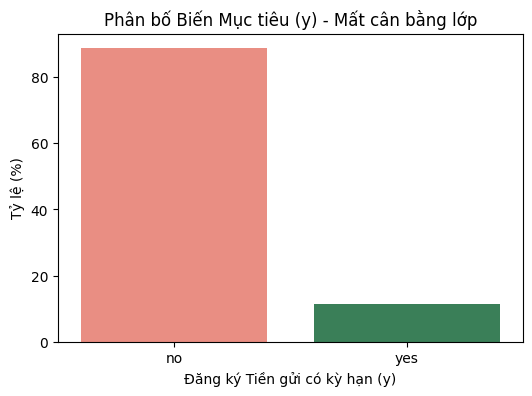

In [22]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Đảm bảo cột mục tiêu 'y' tồn tại
target_col = 'y'

# Nếu bạn đã xóa cột 'y' và chỉ còn 'y_encoded', hãy tạo lại cột 'y' tạm thời:
if target_col not in df.columns and 'y_encoded' in df.columns:
    df[target_col] = df['y_encoded'].apply(lambda x: 'yes' if x == 1 else 'no')
    
# 2. TÍNH TOÁN LẠI BIẾN target_distribution
target_distribution = df[target_col].value_counts(normalize=True) * 100

# 3. VẼ BIỂU ĐỒ (Đoạn code bạn đã cung cấp)
plt.figure(figsize=(6, 4))

# Cập nhật: Thêm hue=target_distribution.index và đặt legend=False
sns.barplot(
    x=target_distribution.index, 
    y=target_distribution.values, 
    hue=target_distribution.index,  # Assign the x variable to hue
    palette=['salmon', 'seagreen'],
    legend=False                   # Set legend=False
)

plt.title('Phân bố Biến Mục tiêu (y) - Mất cân bằng lớp')
plt.ylabel('Tỷ lệ (%)')
plt.xlabel('Đăng ký Tiền gửi có kỳ hạn (y)')
plt.show()

## **III.b.Phân Tích Phân Bố và Giá Trị Ngoại Lệ**
> Bước này đáp ứng yêu cầu "Biểu đồ trực quan (histogram, boxplot)" và giúp tìm kiếm distribution.

> Phân tích Biến Liên tục (Numerical Variables)

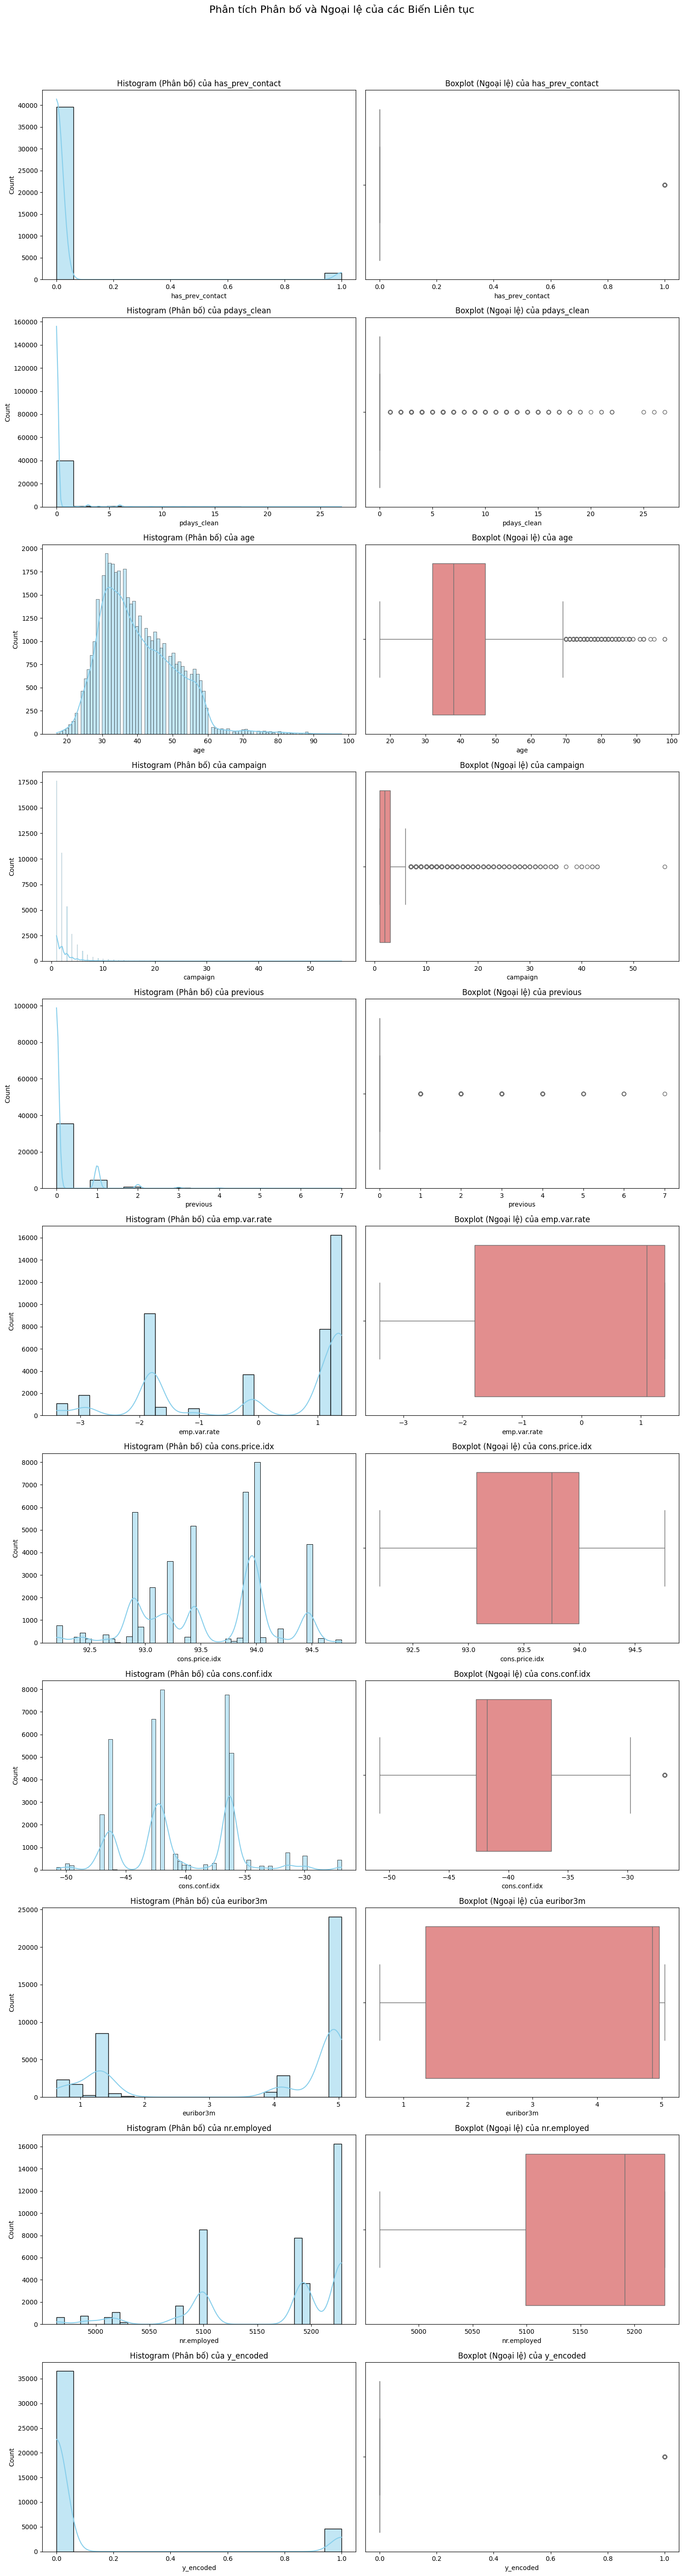

In [23]:
fig, axes = plt.subplots(len(cont_vars), 2, figsize=(15, 5 * len(cont_vars)))
fig.suptitle('Phân tích Phân bố và Ngoại lệ của các Biến Liên tục', fontsize=16, y=1.02)

for i, col in enumerate(cont_vars):
    # Histogram
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Histogram (Phân bố) của {col}')
    
    # Boxplot
    sns.boxplot(x=df[col], ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f'Boxplot (Ngoại lệ) của {col}')
    
plt.tight_layout()
plt.show()

## **III.c. Phân Tích Mối Quan Hệ Biến Phân Loại & Mục Tiêu**
> Bước này giúp xác định các biến phân loại nào có ảnh hưởng lớn đến tỷ lệ đăng ký.

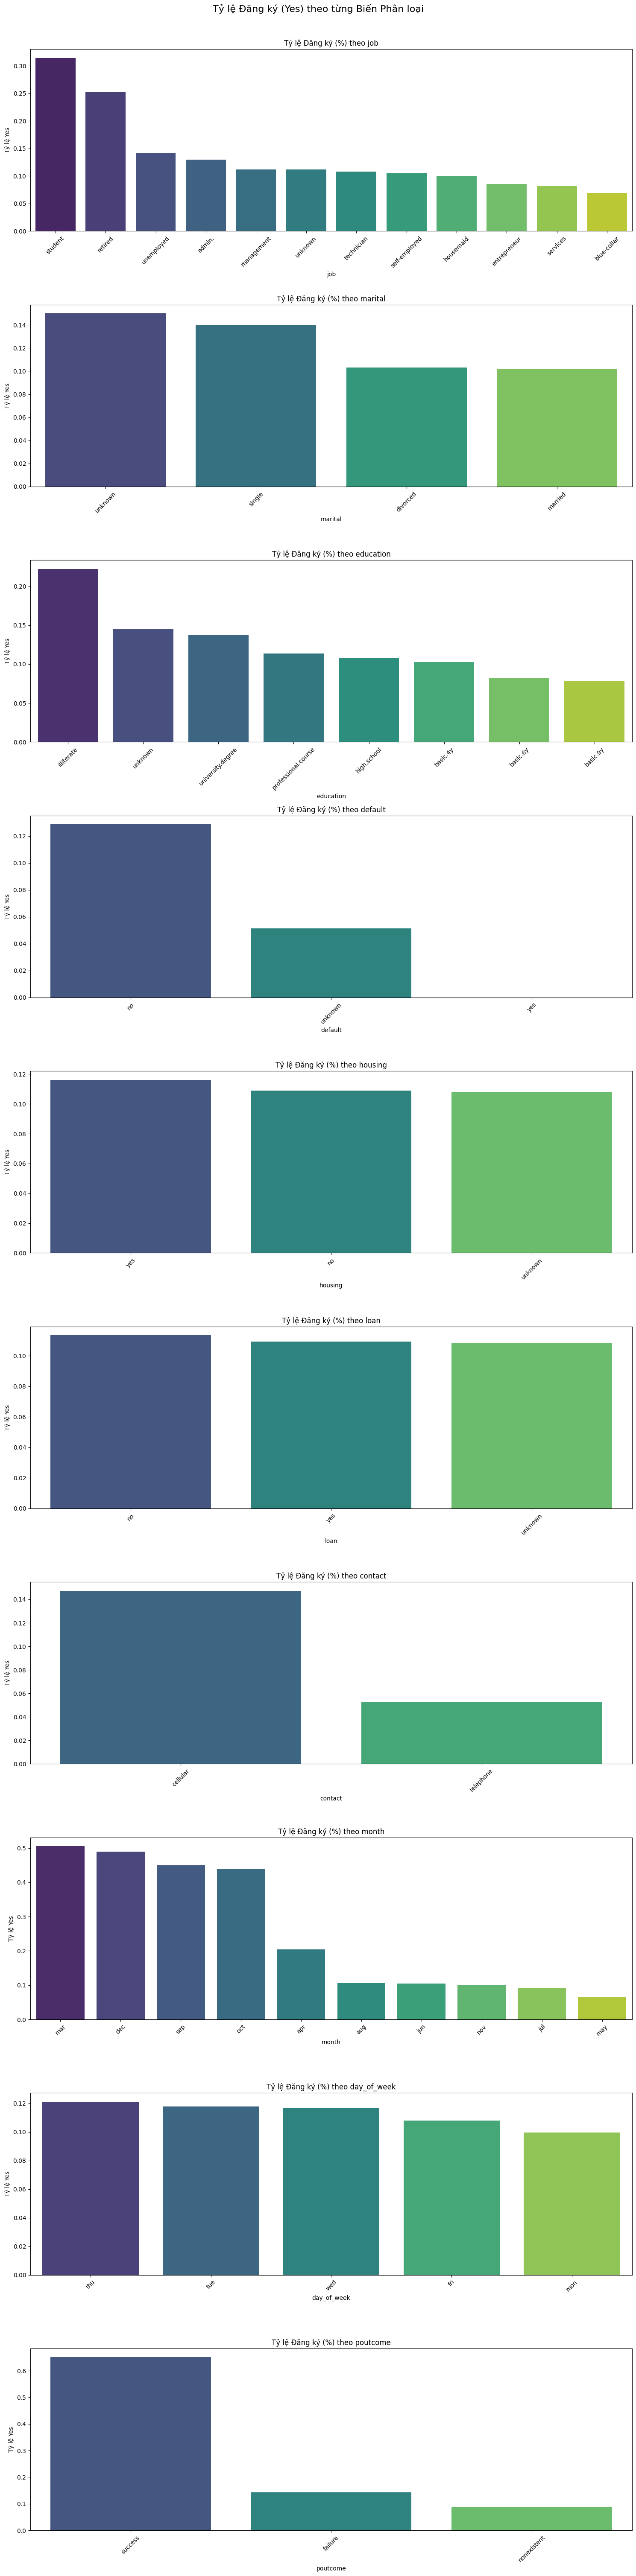

In [24]:
# Xác định cột target tự động
# Nếu đã encode thì y là 0/1 → dùng trực tiếp

# Vẽ biểu đồ conversion rate cho tất cả categorical variables
fig, axes = plt.subplots(len(cat_vars), 1, figsize=(15, 6 * len(cat_vars)))
fig.suptitle('Tỷ lệ Đăng ký (Yes) theo từng Biến Phân loại', fontsize=16, y=1.005)

for i, col in enumerate(cat_vars):

    # Tính conversion rate: trung bình của y (0/1)
    conversion_rate = df.groupby(col)[target].mean().sort_values(ascending=False)

    sns.barplot(
        x=conversion_rate.index,
        y=conversion_rate.values,
        ax=axes[i],
        palette='viridis'
    )

    axes[i].set_title(f'Tỷ lệ Đăng ký (%) theo {col}')
    axes[i].set_ylabel('Tỷ lệ Yes')
    axes[i].set_xlabel(col)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## **III.d.Ma Trận Tương Quan (Correlation Heatmap)**
> Bước này đáp ứng yêu cầu "correlation" và "heatmap".

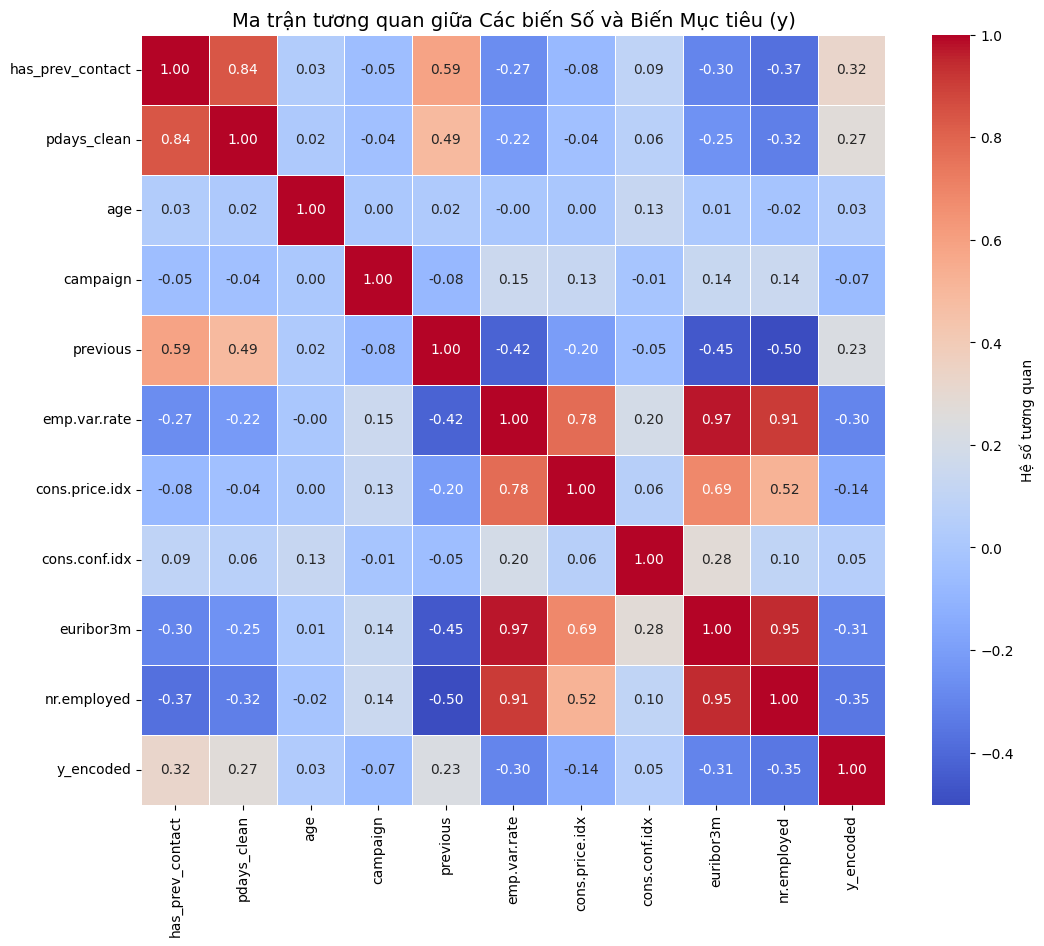

In [25]:

# 4. Lọc lại để chắc chắn chỉ lấy những cột thực sự tồn tại
correlation_cols = [c for c in cont_vars if c in df.columns]

# 5. Vẽ heatmap
plt.figure(figsize=(12, 10))
corr_matrix = df[correlation_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=.5,
    cbar_kws={'label': 'Hệ số tương quan'}
)

plt.title('Ma trận tương quan giữa Các biến Số và Biến Mục tiêu (y)', fontsize=14)
plt.show()


## **III.e.Tỷ lệ đăng ký đóng góp**
- Chiến dịch trước
- Theo số lần liên lạc
- Theo nhóm tuổi
> Dựa kq trước để tham khảo.

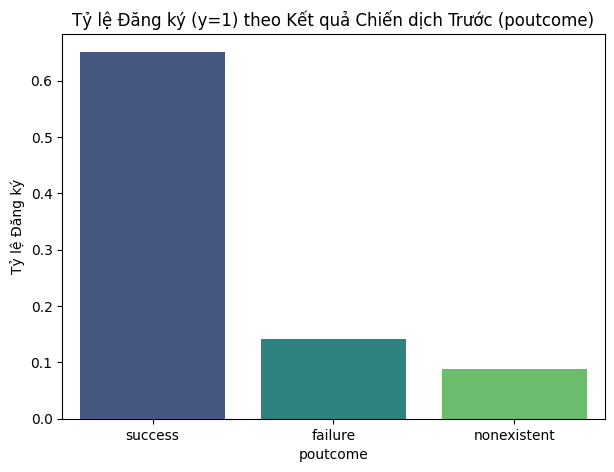

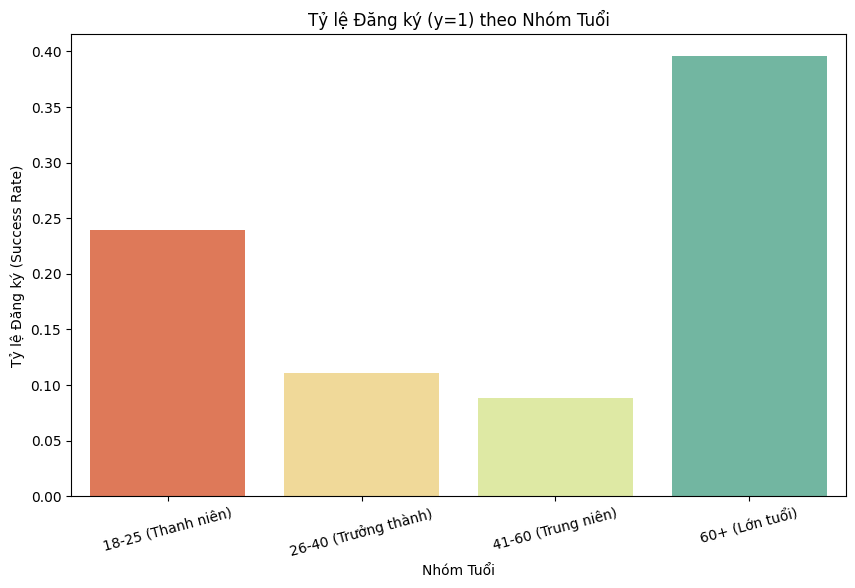

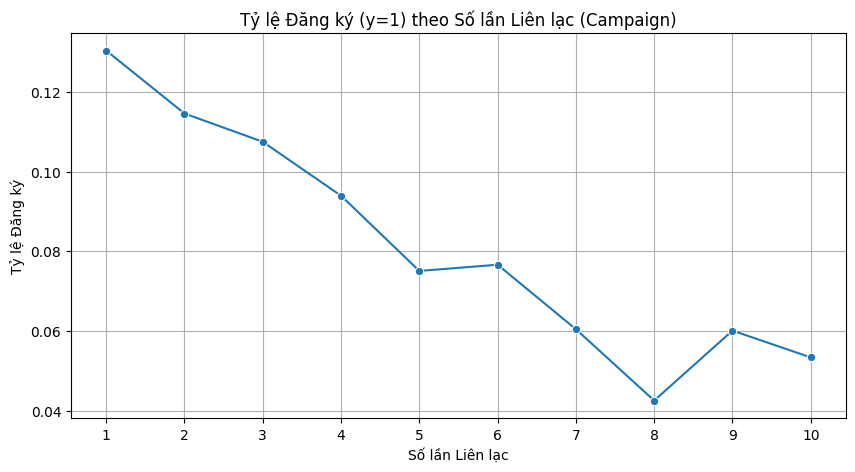

In [26]:
poutcome_success_rate = (
    df.groupby('poutcome')['y_encoded']
    .mean()
    .reset_index()
    .sort_values(by='y_encoded', ascending=False)
)

plt.figure(figsize=(7, 5))
sns.barplot(
    x='poutcome',
    y='y_encoded',   # ✅ sửa ở đây
    data=poutcome_success_rate,
    palette='viridis'
)

plt.title('Tỷ lệ Đăng ký (y=1) theo Kết quả Chiến dịch Trước (poutcome)')
plt.ylabel('Tỷ lệ Đăng ký')
plt.xlabel('poutcome')
plt.show()

bins = [18, 25, 40, 60, 100]
labels = ['18-25 (Thanh niên)', '26-40 (Trưởng thành)', '41-60 (Trung niên)', '60+ (Lớn tuổi)']

df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)

age_group_success_rate = (
    df.groupby('age_group', observed=True)['y_encoded']
    .mean()
    .reset_index()
    .sort_values(by='y_encoded', ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(x='age_group', y='y_encoded', data=age_group_success_rate, palette='Spectral')
plt.title('Tỷ lệ Đăng ký (y=1) theo Nhóm Tuổi')
plt.ylabel('Tỷ lệ Đăng ký (Success Rate)')
plt.xlabel('Nhóm Tuổi')
plt.xticks(rotation=15)
plt.show()

campaign_data = df[df['campaign'] <= 10]

campaign_success_rate = (
    campaign_data.groupby('campaign')['y_encoded']   # ✅ sửa ở đây
    .mean()
    .reset_index()
    .rename(columns={'y_encoded': 'success_rate'})
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    x='campaign',
    y='success_rate',
    data=campaign_success_rate,
    marker='o'
)

plt.title('Tỷ lệ Đăng ký (y=1) theo Số lần Liên lạc (Campaign)')
plt.ylabel('Tỷ lệ Đăng ký')
plt.xlabel('Số lần Liên lạc')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()
df.drop(columns=['age_group'], inplace=True)

 **Phân tích Chi tiết Từng Biểu đồ**

---

1. Phân bố Biến Mục tiêu (y) - Mất cân bằng lớp (image_bb4e15.png)

  - **Insight:**  
      Dữ liệu mất cân bằng nghiêm trọng, lớp không đăng ký (y=0) chiếm khoảng 90%, lớp đăng ký (y=1) chỉ khoảng 10%.

  - **Ý nghĩa:**  
      Cần áp dụng kỹ thuật xử lý mất cân bằng như SMOTE hoặc điều chỉnh trọng số lớp để mô hình dự đoán chính xác lớp thiểu số.

---

2. Tỷ lệ Đăng ký (y=1) theo Kết quả Chiến dịch Trước (poutcome)

  - **Insight:**  
    Kết quả chiến dịch trước (poutcome) là yếu tố dự đoán rất mạnh.  
    Khách hàng có poutcome = "success" có tỷ lệ đăng ký hiện tại rất cao (~65%).  
    Nhóm "failure" và "nonexistent" có tỷ lệ thấp (9%-14%).  

  - **Ý nghĩa:**  
    Ưu tiên tập trung tiếp thị nhóm khách hàng từng thành công trong chiến dịch trước.

---

3. Tỷ lệ Đăng ký (y=1) theo Số lần Liên lạc (Campaign)

  - **Insight:**  
    Tỷ lệ đăng ký cao nhất ở lần liên lạc đầu (~12.5%), giảm dần khi số lần liên lạc tăng.  
    Liên lạc quá nhiều lần có thể phản tác dụng hoặc chỉ tiếp cận khách hàng khó chuyển đổi.  

  - **Ý nghĩa:**  
    Tối ưu số lần liên lạc, tập trung nâng cao chất lượng cuộc gọi đầu tiên.

---

4. Tỷ lệ Đăng ký (y=1) theo Nhóm Tuổi

  - **Insight:**  
    Nhóm tuổi 60+ có tỷ lệ đăng ký cao nhất (~40%), nhóm 18-25 cũng cao (~24%).  
    Các nhóm tuổi trung niên, lao động chính có tỷ lệ thấp hơn (~9-11%).  

  - **Ý nghĩa:**  
    Tập trung chiến dịch vào hai nhóm tuổi này với thông điệp phù hợp.

---

5. Ma trận tương quan giữa Các Biến số và Biến Mục tiêu (y)

  - **Insight:**  
    - Tương quan dương khác: `has_prev_contact` (0.32), `pdays_clean` (0.27).  
    - Tương quan âm mạnh với `nr.employed` (-0.34), `euribor3m` (-0.31), `emp.var.rate` (-0.27).  

  - **Ý nghĩa:**  
    Khách hàng có xu hướng đăng ký khi các chỉ số kinh tế vĩ mô giảm hoặc bất ổn, tìm kiếm sự an toàn tài chính.

---

6. Phân bố và Tỷ lệ Đăng ký theo Biến Định tính 

  - **Insight:**  
    - Nghề nghiệp: nhóm sinh viên và nghỉ hưu có tỷ lệ đăng ký cao nhất.  
    - Phương tiện liên lạc: cellular hiệu quả hơn telephone.  
    - Tháng: tháng 3, 9, 10, 12 có tỷ lệ đăng ký cao hơn.  

  - **Ý nghĩa:**  
    Ưu tiên dùng điện thoại di động, tập trung chiến dịch vào các tháng có tỷ lệ chuyển đổi cao, nhắm tới nhóm sinh viên và người nghỉ hưu.

---

7. Phân bố Biến Định lượng

  - **Insight:**  
    Các biến định lượng như age, campaign, duration, pdays có phân bố lệch phải mạnh, nhiều giá trị ngoại lai.  
    
  - **Ý nghĩa:**  
    Cần xử lý biến đổi (log-transform hoặc tương tự) để phù hợp với mô hình tuyến tính hoặc mô hình nhạy cảm phân phối.


# **IV.Xây dựng hướng đi**

## **IV.a.Xác định hướng đi**

### **IV.a.1.Giới thiệu mô hình và thang đo**
**Giới thiệu các mô hình sẽ xây dựng**
- Phân lớp: Random forest,LightGBM,xgboost
- Gom cụm: K-Means, Hierarchical Clusteing

**Giới thiệu các thang đo đánh giá**
- Phân lớp: Accuracy (Độ chính xác), Confusion Matrix, Precision (Độ chuẩn xác), Recall (Độ nhạy/Độ phủ), F1-Score, AUC-ROC.
- Gom cụm: Silhouette Score, Inertia (SSE), Tính Khả giải thích (Interpretability)

### **IV.a.2.Chi tiết**
**Chi tiết các mô hình sẽ xây dựng**

- Random Forest
    - Đ/N: **Mô hình phân lớp rừng ngẫu nhiên, sử dụng nhiều cây quyết định để cải thiện hiệu suất và giảm overfitting.**
    - Ưu điểm: **Hiệu quả, ít overfitting, dễ diễn giải, khả năng xử lý dữ liệu phi tuyến phức tạp.**
    - Nhược điểm: **Tốn thời gian huấn luyện, khó diễn giải, khó tối ưu.**

- LightGBM
    - Đ/N: **Thuật toán boosting dựa trên cây quyết định, tối ưu theo hướng học nhanh và nhẹ cho dữ liệu lớn.**
    - Ưu điểm: **Huấn luyện rất nhanh, hiệu suất cao, xử lý tốt dữ liệu lớn và nhiều chiều.**
    - Nhược điểm: **Dễ overfitting nếu không tuning tốt, khó diễn giải.**

- Xgboost
    - Đ/N: **Thuật toán boosting cải tiến từ Gradient Boosting, tối ưu bằng đạo hàm bậc hai và regularization**
    - Ưu điểm: **Độ chính xác rất cao, kiểm soát overfitting tốt, ổn định**
    - Nhược điểm: **Huấn luyện chậm hơn LightGBM, nhiều tham số cần tinh chỉnh**

- K-Means
    - Đ/N: **Thuật toán gom cụm bằng cách chia dữ liệu thành K cụm sao cho khoảng cách trong cụm nhỏ nhất.**
    - Ưu điểm: **Dễ cài đặt, chạy nhanh, phù hợp với dữ liệu lớn.**
    - Nhược điểm: **Cần xác định số lượng cụm trước, dễ bị ảnh hưởng bởi nhiễu.**

- Hierarchical Clustering
    - Đ/N: **Thuật toán gom cụm dựa trên phân cấp, tạo cây phân cấp (dendrogram).**
    - Ưu điểm: **Không cần chọn trước số cụm, dễ trực quan hóa cấu trúc dữ liệu.**
    - Nhược điểm: **Tốn thời gian và bộ nhớ, không phù hợp với tập dữ liệu lớn.**

**Chi tiết các thang đo đánh giá**

- **Phân lớp (Classification Metrics)**

1. Accuracy (Độ chính xác)  
    - **Định nghĩa:** Tỷ lệ dự đoán đúng trên tổng số mẫu.  
    - **Công thức:**  
    \[
    \text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
    \]

---

2. Confusion Matrix (Ma trận nhầm lẫn)  
    - **Định nghĩa:** Bảng thể hiện số lượng dự đoán đúng/sai cho từng lớp.  
    - **Cấu trúc:**

    | Thực tế \ Dự đoán | Positive | Negative |
    |-------------------|----------|----------|
    | Positive          | TP       | FN       |
    | Negative          | FP       | TN       |

---

3. Precision (Độ chuẩn xác)  
    - **Định nghĩa:** Tỷ lệ dự đoán đúng trong các mẫu được dự đoán là dương tính.  
    - **Công thức:**  
    \[
    \text{Precision} = \frac{TP}{TP + FP}
    \]

---

4. Recall (Độ nhạy / Độ phủ)  
    - **Định nghĩa:** Tỷ lệ phát hiện đúng các mẫu dương tính thực tế.  
    - **Công thức:**  
    \[
    \text{Recall} = \frac{TP}{TP + FN}
    \]

---

5. F1-Score  
    - **Định nghĩa:** Trung bình điều hòa giữa Precision và Recall.  
    - **Công thức:**  
    \[
    F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
    \]

---

6. AUC–ROC  
    - **Định nghĩa:** Diện tích dưới đường cong ROC (True Positive Rate theo False Positive Rate).  
    - **Công thức:**

        \[
        TPR = \frac{TP}{TP + FN}, \quad FPR = \frac{FP}{FP + TN}
        \]

---

- **Gom cụm (Clustering Metrics)**

1. Silhouette Score  
    - **Định nghĩa:** Đo mức độ tương đồng của một điểm với cụm của nó so với các cụm khác.  
    - **Công thức:**  
    \[
    S(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}
    \]

    Trong đó:  
    - \(a(i)\): khoảng cách trung bình từ điểm \(i\) đến các điểm trong cùng cụm.  
    - \(b(i)\): khoảng cách trung bình nhỏ nhất từ điểm \(i\) đến các điểm trong cụm gần nhất khác.

---

2. Inertia (SSE – Sum of Squared Errors)  
    - **Định nghĩa:** Tổng bình phương khoảng cách từ các điểm đến tâm cụm.  
    - **Công thức:**  
    \[
    SSE = \sum_{i=1}^{k} \sum_{x \in C_i} \| x - \mu_i \|^2
    \]

    Trong đó:  
    - \(C_i\): cụm thứ \(i\).  
    - \(\mu_i\): tâm cụm \(i\).

---

3. **Tính Khả Giải Thích (Interpretability)**

    - **Định nghĩa:** Mức độ mà con người có thể hiểu được cách mô hình phân cụm hoạt động và ý nghĩa của từng cụm.  
    - **Lưu ý:** Không có công thức toán học cố định, thường được đánh giá định tính dựa trên tính đơn giản, trực quan và khả năng giải thích của mô hình.





### **IV.b.Hướng xử lý dữ liệu nâng cao**


**Kế hoạch Xử lý Dữ liệu và Kỹ thuật Mô hình**
- Từ kết quả và insights, ta có thể tóm tắt các vấn đề cần giải quyết để xây dựng mô hình:

**1. Mất cân bằng lớp (Phân bố y)**  
- Kỹ thuật đề xuất: SMOTE hoặc Điều chỉnh trọng số lớp (Class Weights)  
- Giải thích/Mục tiêu:  
  Lớp thiểu số (y=1) chỉ chiếm ~10%. Cần cân bằng lại dữ liệu để mô hình không thiên vị dự đoán lớp đa số (y=0), đảm bảo khả năng dự đoán chính xác lớp đăng ký.

**2. Biến định tính (poutcome, job, marital, contact, month, v.v.)**  
- Kỹ thuật đề xuất: One-Hot Encoding  
- Giải thích/Mục tiêu:  
  Các thuật toán máy học yêu cầu đầu vào là số. One-Hot Encoding tạo ra các cột nhị phân cho mỗi giá trị danh mục, loại bỏ quan hệ thứ bậc giả định và giúp mô hình hiểu được tầm quan trọng của từng hạng mục (ví dụ: poutcome là biến dự đoán mạnh mẽ).

**3. Biến có nhiều giá trị (month, day_of_week)**  
- Kỹ thuật đề xuất: Target Encoding (Mean Encoding) hoặc one-hot encoding
- Giải thích/Mục tiêu:  
  Đối với các biến danh mục có nhiều giá trị hoặc biến có quan hệ đơn điệu với biến mục tiêu (ví dụ: tháng 3, 9, 10, 12 có tỷ lệ đăng ký cao hơn), Target Encoding có thể hiệu quả hơn One-Hot Encoding, giảm số chiều và tăng cường sức mạnh dự đoán.

**4. Biến định lượng lệch (age, campaign, pdays_clean)**  
- Kỹ thuật đề xuất: Biến đổi log/căn (Log/Square Root Transformation) hoặc Robust Scaler  
- Giải thích/Mục tiêu:  
  Phân bố lệch phải mạnh và có nhiều giá trị ngoại lai (outliers). Biến đổi giúp phân phối gần với phân phối chuẩn hơn, cải thiện hiệu suất của các mô hình tuyến tính (như Hồi quy Logistic) và xử lý tốt hơn các giá trị ngoại lai.

**5. Giảm số chiều/Đa cộng tuyến**  
- Kỹ thuật đề xuất: Chọn lọc Đặc trưng (Feature Selection) hoặc PCA (Principal Component Analysis)  
- Giải thích/Mục tiêu:  
  - Chọn lọc Đặc trưng: Ưu tiên giữ lại các biến có tương quan mạnh với *y* (như các biến chỉ số kinh tế vĩ mô: nr.employed, euribor3m, emp.var.rate - tương quan âm) và các biến có ý nghĩa kinh doanh (như poutcome).  
  - PCA: Có thể áp dụng sau khi mã hóa các biến để giảm số chiều, đặc biệt nếu có đa cộng tuyến giữa các biến kinh tế vĩ mô (tương quan chặt chẽ với nhau).
---

## **IV.c.Xác định hướng tập trung tối ưu và đánh giá sau xây dựng**

**Tối ưu hóa mô hình**  
- Kỹ thuật đề xuất: OPTUNA

- Giải thích/Mục tiêu: OPTUNA là một thư viện tối ưu tham số tự động (hyperparameter optimization) cho các mô hình Machine Learning. Mục tiêu của OPTUNA là tìm ra bộ tham số tối ưu giúp cải thiện hiệu suất của mô hình (ví dụ: tăng độ chính xác, F1-score, giảm loss, MAE…). OPTUNA sử dụng các thuật toán như Bayesian optimization và Tree-structured Parzen Estimator (TPE) để lựa chọn tham số thông minh, đồng thời hỗ trợ early stopping để giảm thời gian chạy thử nghiệm không cần thiết



====================================================================

**Đánh giá mô hình**  
- Kỹ thuật đề xuất: Các thang đo đánh giá đã được nêu.
- Giải thích/Mục tiêu:  
  - Do mất cân bằng lớp, các chỉ số như Accuracy (Độ chính xác) không đáng tin cậy.
  - Trong phân lớp, ta tập trung vào f1 và auc/roc, vì:
    -  Mục tiêu Kinh doanh: Trong Marketing mục tiêu, ngân hàng cần sự cân bằng giữa việc giảm lãng phí nguồn lực (cần Precision cao, tránh liên hệ người không quan tâm) và tối đa hóa cơ hội bán hàng (cần Recall cao, tránh bỏ sót khách hàng tiềm năng). F1-Score là chỉ số duy nhất đo lường sự cân bằng chiến lược này. 
  - kẾT LUẬN: CHỌN RA MÔ HÌNH CHO RA 3 CON SỐ KHÔNG QUÁ CHÊNH LỆCH NHAU NHẤT

    - AUC/ROC:AUC (Area Under the ROC Curve) đo lường khả năng phân tách giữa lớp dương (y=yes) và lớp âm (y=no) của mô hình, không phụ thuộc vào ngưỡng (threshold) phân loại cụ thể.Mục tiêu Kỹ thuật: Cung cấp cái nhìn toàn diện về hiệu suất của mô hình, đặc biệt quan trọng để so sánh khách quan các thuật toán khác nhau (ví dụ: Logistic Regression, Random Forest, XGBoost).
    
  - Trong Gom cụm, ta tập trung vào Silhouette và Tính Khả Giải Thích, vì:
    - Silhouette Score: Chỉ số này đánh giá mức độ tách biệt của các cụm (khoảng cách giữa các cụm) và mức độ đồng nhất của các điểm dữ liệu trong cùng một cụm.

      - Mục tiêu Phân khúc: Để xây dựng các chiến lược tiếp thị khác biệt, các phân khúc (cụm) cần phải rõ ràng, tách biệt và đồng nhất bên trong. Silhouette Score giúp tìm ra số lượng cụm tối ưu ($K$) để đạt được sự phân biệt rõ ràng này.

    - Tính Khả Giải Thích (Interpretability) / Cluster Profiling: Đây là bước chuyển đổi kết quả toán học (các cụm) thành Insight kinh doanh có thể hành động.

      - Mục tiêu Kinh doanh: Ngân hàng cần hiểu đặc điểm của từng cụm (tuổi trung bình, nghề nghiệp, tỷ lệ chuyển đổi trong quá khứ) để đặt tên và thiết kế thông điệp/chiến lược tiếp thị riêng biệt cho từng nhóm (ví dụ: "Nhóm Hưu trí giàu có" cần thông điệp ổn định, "Nhóm Chuyên gia trẻ" cần thông điệp tiện lợi). Nếu không có khả năng giải thích, kết quả gom cụm chỉ là những con số vô nghĩa.

# **V.Xử lý dữ liệu nâng cao**

## **V.a. Quy trình chuẩn và các phương pháp xử lý dữ liệu nâng cao phổ biến**

**1. Xử lý Ngoại lai & Tạo Thuộc tính (Outlier Treatment & Feature Engineering)**

- **Xử lý Ngoại lai (Outlier Treatment):**  
  Phát hiện và xử lý các giá trị bất thường bằng cách loại bỏ hoặc giới hạn (capping/flooring) giúp dữ liệu ổn định, giảm ảnh hưởng tiêu cực của outliers.  
  Ví dụ: Biến đổi Log/Square Root hoặc dùng Robust Scaler cho các biến lệch như *age*, *campaign*, *pdays*.

- **Tạo Thuộc tính mới (Feature Engineering):**  
  Tạo biến mới có giá trị dự đoán cao hơn từ dữ liệu gốc (ví dụ: *pdays_clean*, biến nhị phân từ *poutcome*, biến chu kỳ *month*, *day_of_week*).  
  Bước sáng tạo quan trọng trước khi mã hóa và chuẩn hóa.


- **PCA TẠO CỘT MỚI DÙ GIẢM CHIỀU**
---


**2. Chuẩn hóa & Chia Dữ liệu (Scaling & Splitting)**

- **Chia tập dữ liệu:**  
  Bắt buộc chia thành Train/Validation/Test để tránh rò rỉ dữ liệu (Data Leakage) và đảm bảo mô hình tổng quát tốt.

- **Chuẩn hóa dữ liệu:**  
  Điều chỉnh thang đo các biến số (ví dụ: *age*, *balance*) bằng Standard Scaler hoặc ưu tiên Robust Scaler do có outliers, giúp mô hình dựa trên khoảng cách và ML hoạt động hiệu quả hơn.

- **Xử lý Thuộc tính Chu kỳ (Cyclical Feature):**  
  Áp dụng biến đổi Sin/Cos cho các biến tuần hoàn (ví dụ: tháng, ngày trong tuần) giúp mô hình hiểu tính liên tục và tuần hoàn.

- **Encoding (Mã hóa biến phân loại):**  
  Chuyển đổi biến định tính thành số để mô hình ML xử lý được.  
  - One-Hot Encoding cho các biến cần thiết
---

**3. Tối ưu hóa Mô hình (Model Optimization)**

- **SMOTE (Xử lý mất cân bằng lớp):**  
  Tạo mẫu tổng hợp cho lớp thiểu số (~10%) giúp cân bằng dữ liệu, tránh mô hình thiên vị lớp đa số.

- **Chọn lọc Thuộc tính (Feature Selection):**  
  Loại bỏ biến không cần thiết hoặc dư thừa để tăng tốc độ huấn luyện, giảm phức tạp và cải thiện khả năng giải thích. Ưu tiên giữ biến có tương quan mạnh với biến mục tiêu.

- **PCA (Phân tích Thành phần Chính):**  
  Giảm số chiều dữ liệu, giải quyết đa cộng tuyến giữa các biến kinh tế vĩ mô, giúp mô hình ổn định và dễ giải thích hơn. Thường áp dụng sau mã hóa và chỉ trên biến số.

---

**4. Xác định phương pháp sử dụng - Lý do chọn lựa**

| Phương pháp                  | Lý do chọn lựa chính                                                                                           |
|-----------------------------|---------------------------------------------------------------------------------------------------------------|
| **Xử lý Ngoại lai**         | Dữ liệu có phân phối lệch, nhiều outliers ảnh hưởng tiêu cực; dùng biến đổi Log/Sqrt hoặc Robust Scaler.       |
| **Tạo Thuộc tính mới**       | Tăng sức mạnh dự đoán từ dữ liệu thô, khai thác biến chu kỳ và biến nhị phân từ biến gốc.                      |
| **Encoding**                | Bắt buộc để biến phân loại thành số; One-Hot cho biến không có thứ bậc     |
| **Xử lý Thuộc tính Chu kỳ** | Giúp mô hình hiểu tính tuần hoàn của tháng, ngày trong tuần qua biến đổi Sin/Cos.                              |
| **Chia dữ liệu**            | Ngăn ngừa Data Leakage, đảm bảo mô hình tổng quát và đánh giá chính xác.                                       |
| **Chuẩn hóa**               | Biến có phạm vi khác nhau, Robust Scaler giúp xử lý outliers và tăng hiệu quả mô hình.                         |
| **SMOTE**                   | Cân bằng lớp thiểu số (~10%) để tránh thiên vị mô hình.                                                        |
| **Chọn lọc Thuộc tính**     | Loại bỏ biến ít liên quan, tăng tốc độ, giảm phức tạp, nâng cao khả năng giải thích.                           |
| **PCA**                     | Giải quyết đa cộng tuyến, giảm chiều, giúp mô hình ổn định, dễ giải thích, đặc biệt với biến kinh tế vĩ mô.    |

---

**Tóm lại:** Quy trình xử lý dữ liệu bắt đầu từ xử lý ngoại lai và tạo biến mới, tiếp đến mã hóa và chuẩn hóa, chia dữ liệu đúng cách, cuối cùng là tối ưu mô hình qua cân bằng lớp, chọn lọc biến và giảm chiều bằng PCA để đạt hiệu quả và độ chính xác cao nhất cho bài toán học máy.

**Lứu ý: Mã hoá luôn các cột unknow ở phần đầu xem cấu trúc dữ liệu**

## **V.b.Thực hiện**

In [27]:
df.drop('y', axis=1, inplace=True)
df.head()

,has_prev_contact,pdays_clean,age,job,marital,education,default,housing,loan,contact,...,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y_encoded
0,0,0,56,housemaid,married,basic.4y,no,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,0,0,57,services,married,high.school,unknown,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,0,0,37,services,married,high.school,no,yes,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,0,0,40,admin.,married,basic.6y,no,no,no,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,0,0,56,services,married,high.school,no,no,yes,telephone,...,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_score, 
    recall_score, f1_score, roc_auc_score, roc_curve, auc
)
from imblearn.over_sampling import SMOTE
import lightgbm as lgb
import xgboost as xgb
# Thư viện cho Feature Selection
from sklearn.feature_selection import SelectFromModel

# Thiết lập hiển thị và kiểu đồ thị
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_style("whitegrid")


print("--- KHỞI ĐỘNG QUY TRÌNH TIỀN XỬ LÝ ---")

# ----------------------------------------------------------------------
## 1. Xử lý Ngoại lai & Xử lý 'unknown'
# ----------------------------------------------------------------------

print("\n[BƯỚC 1] Xử lý Ngoại lai & Tạo Thuộc tính...")
df_processed = df.copy()

numerical_outlier_cols = ['campaign', 'previous'] 
for col in numerical_outlier_cols:
    if col in df_processed.columns:
        upper_bound = df_processed[col].quantile(0.99)
        lower_bound = df_processed[col].quantile(0.01)
        df_processed[col] = np.where(df_processed[col] > upper_bound, upper_bound, df_processed[col])
        df_processed[col] = np.where(df_processed[col] < lower_bound, lower_bound, df_processed[col])
        
categorical_unknown_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan'] 
for col in categorical_unknown_cols:
    if col in df_processed.columns:
        df_processed[col] = df_processed[col].replace('unknown', 'Unknown_Category')
        
df = df_processed.copy()
print("-> Đã thay thế giá trị 'unknown' thành 'Unknown_Category' trong các biến phân loại.")
print("[BƯỚC 1] Hoàn tất Capping/Flooring và Xử lý 'unknown'.")

# ----------------------------------------------------------------------
## 2. CHIA TẬP DỮ LIỆU
# ----------------------------------------------------------------------

print("\n[BƯỚC 2] Bắt đầu Chia tập dữ liệu (Train/Validation/Test)...")
X = df.drop('y_encoded', axis=1)
y = df['y_encoded']

# *** HIỂN THỊ SỐ CỘT TRƯỚC TIỀN XỬ LÝ ***
print(f"\n📊 SỐ CỘT TRƯỚC TIỀN XỬ LÝ (PCA/Feature Selection): {X.shape[1]} cột")

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)
print("[BƯỚC 2] Hoàn tất chia tập dữ liệu.")

# ----------------------------------------------------------------------
## 3. Xử lý Định dạng & Chuẩn hóa
# ----------------------------------------------------------------------

# --- 3.1. Xác định các cột ---
numerical_cols = ['campaign', 'previous', 'pdays_clean']
cyclical_cols = ['month', 'day_of_week']
ohe_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome'] 
pca_cols = ['euribor3m', 'nr.employed', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx']

# --- 3.2. Xử lý Thuộc tính Chu kỳ (Cyclical Feature) ---
def encode_cyclical(data):
    data_copy = data.copy()
    if 'month' in data_copy.columns:
        month_codes = data_copy['month'].astype('category').cat.codes
        data_copy['month_sin'] = np.sin(2 * np.pi * month_codes / 12)
        data_copy['month_cos'] = np.cos(2 * np.pi * month_codes / 12)
        data_copy.drop(columns=['month'], inplace=True)
    if 'day_of_week' in data_copy.columns:
        day_codes = data_copy['day_of_week'].astype('category').cat.codes
        data_copy['day_sin'] = np.sin(2 * np.pi * day_codes / 7)
        data_copy['day_cos'] = np.cos(2 * np.pi * day_codes / 7)
        data_copy.drop(columns=['day_of_week'], inplace=True)
    return data_copy

# --- 3.3. Xây dựng ColumnTransformer ---
print("\n[BƯỚC 3] Áp dụng ColumnTransformer (RobustScaler, OHE, PCA)...")

preprocessor = ColumnTransformer(
    transformers=[
        ('num_robust', RobustScaler(), numerical_cols), 
        ('pca_macro', Pipeline(steps=[('scaler', RobustScaler()), ('pca', PCA(n_components=2))]), pca_cols),
        ('ohe', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), ohe_cols), # Thêm handle_unknown
    ],
    remainder='passthrough', 
    verbose_feature_names_out=False
).set_output(transform="pandas")

# Áp dụng Preprocessor
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Xử lý Thuộc tính Chu kỳ
X_train_processed = encode_cyclical(X_train_processed)
X_val_processed = encode_cyclical(X_val_processed)
X_test_processed = encode_cyclical(X_test_processed)

print(f"-> Số cột sau Scaling/Encoding/PCA: {X_train_processed.shape[1]} cột")

# ----------------------------------------------------------------------
## 3.5. LỰA CHỌN THUỘC TÍNH (FEATURE SELECTION) MỚI
# ----------------------------------------------------------------------

print("\n[BƯỚC 3.5] Bắt đầu Lựa chọn thuộc tính bằng SelectFromModel...")
N_before_fs = X_train_processed.shape[1]

# 1. Huấn luyện mô hình Random Forest cơ bản để đánh giá tầm quan trọng
fs_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
fs_model.fit(X_train_processed, y_train)

# 2. Định nghĩa Feature Selector (Chọn các feature có Importance > Median)
# Threshold='median' là một lựa chọn cân bằng giữa việc giữ lại thuộc tính và giảm chiều.
selector = SelectFromModel(fs_model, threshold='median', prefit=True)

# 3. Áp dụng Selector lên các tập dữ liệu
X_train_fs = selector.transform(X_train_processed)
X_val_fs = selector.transform(X_val_processed)
X_test_fs = selector.transform(X_test_processed)

# Lấy tên các cột đã được chọn
selected_features = X_train_processed.columns[selector.get_support()]

# Gán lại DataFrame với các cột đã chọn
X_train_processed = pd.DataFrame(X_train_fs, columns=selected_features, index=X_train_processed.index)
X_val_processed = pd.DataFrame(X_val_fs, columns=selected_features, index=X_val_processed.index)
X_test_processed = pd.DataFrame(X_test_fs, columns=selected_features, index=X_test_processed.index)

N_after_fs = X_train_processed.shape[1]
print(f"-> Đã giảm số cột từ {N_before_fs} xuống {N_after_fs} cột.")
print("[BƯỚC 3.5] Hoàn tất Lựa chọn thuộc tính.")


# ----------------------------------------------------------------------
## 4. Tối ưu hóa Mô hình (SMOTE)
# ----------------------------------------------------------------------

# --- 4.1. SMOTE (Xử lý Mất cân bằng lớp) ---
if y_train.shape[0] < y_train.value_counts().sum() * 1.5: 
    print("\n-> Áp dụng SMOTE lên tập Huấn luyện với tỷ lệ thiểu số/đa số là 1:4 (0.25)...")
    
    smote = SMOTE(sampling_strategy=0.25, random_state=42) 
    # Áp dụng SMOTE lên tập đã qua Feature Selection
    X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)

    X_train = X_train_smote.copy()
    y_train = y_train_smote.copy()
    
    N_0 = y_train.value_counts().max()
    N_1 = y_train.value_counts().min()
    print(f"-> Phân phối lớp sau SMOTE: Đa số (0): {N_0}, Thiểu số (1): {N_1}")
else:
    print("-> Không cần áp dụng SMOTE.")

X_val = X_val_processed.copy()
X_test = X_test_processed.copy()
    
print("\n[BƯỚC 4] Hoàn tất Tối ưu hóa Mô hình (SMOTE).")
print(f"Kích thước tập Huấn luyện cuối cùng: X={X_train.shape}, Y={y_train.shape}")
print(f"Kích thước tập Kiểm tra cuối cùng: X={X_test.shape}, Y={y_test.shape}")

# *** HIỂN THỊ SỐ CỘT SAU TIỀN XỬ LÝ CUỐI CÙNG ***
print("\n" + "="*80)
print("📊 KẾT QUẢ SAU TIỀN XỬ LÝ (PCA + Feature Selection + Feature Engineering)")
print("="*80)
print(f"✓ Số cột SAU tiền xử lý cuối cùng: {X_train.shape[1]} cột")
print(f"\n📋 Danh sách cột sau tiền xử lý:")
for i, col in enumerate(X_train.columns, 1):
    print(f"   {i:2d}. {col}")

print("\n" + "="*80)
print("--- QUY TRÌNH TIỀN XỬ LÝ DỮ LIỆU NÂNG CAO HOÀN TẤT ---")
print("="*80)

--- KHỞI ĐỘNG QUY TRÌNH TIỀN XỬ LÝ ---

[BƯỚC 1] Xử lý Ngoại lai & Tạo Thuộc tính...
-> Đã thay thế giá trị 'unknown' thành 'Unknown_Category' trong các biến phân loại.
[BƯỚC 1] Hoàn tất Capping/Flooring và Xử lý 'unknown'.

[BƯỚC 2] Bắt đầu Chia tập dữ liệu (Train/Validation/Test)...

📊 SỐ CỘT TRƯỚC TIỀN XỬ LÝ (PCA/Feature Selection): 20 cột
[BƯỚC 2] Hoàn tất chia tập dữ liệu.

[BƯỚC 3] Áp dụng ColumnTransformer (RobustScaler, OHE, PCA)...
-> Số cột sau Scaling/Encoding/PCA: 49 cột

[BƯỚC 3.5] Bắt đầu Lựa chọn thuộc tính bằng SelectFromModel...
-> Đã giảm số cột từ 49 xuống 25 cột.
[BƯỚC 3.5] Hoàn tất Lựa chọn thuộc tính.

-> Áp dụng SMOTE lên tập Huấn luyện với tỷ lệ thiểu số/đa số là 1:4 (0.25)...
-> Phân phối lớp sau SMOTE: Đa số (0): 29238, Thiểu số (1): 7309

[BƯỚC 4] Hoàn tất Tối ưu hóa Mô hình (SMOTE).
Kích thước tập Huấn luyện cuối cùng: X=(36547, 25), Y=(36547,)
Kích thước tập Kiểm tra cuối cùng: X=(4119, 25), Y=(4119,)

📊 KẾT QUẢ SAU TIỀN XỬ LÝ (PCA + Feature Selection + Fea

**Giải Thích Quy Trình Tiền Xử Lý Dữ Liệu Nâng Cao**

Quy trình xây dựng là một luồng công việc toàn diện, bao gồm các kỹ thuật tiên tiến để chuẩn bị dữ liệu cho mô hình học máy, tập trung xử lý các vấn đề ngoại lai, mất cân bằng lớp và đa cộng tuyến.

---

**1. Bước Dọn Dẹp và Xử Lý Giá Trị**

- **Xử Lý Ngoại Lai (Outlier Treatment)**  
  - Kỹ thuật: Capping và Flooring (Giới hạn giá trị).  
  - Thực hiện: Các biến *campaign* và *previous* được giới hạn trong khoảng từ phân vị 1% (P1) đến phân vị 99% (P99).  
  - Mục đích: Giảm thiểu ảnh hưởng tiêu cực của các giá trị cực đoan đối với việc huấn luyện mô hình, đặc biệt khi sử dụng RobustScaler sau này.

- **Xử Lý Danh Mục 'Unknown'**  
  - Thực hiện: Các giá trị 'unknown' trong các biến phân loại (job, marital, education, v.v.) được thay thế thành 'Unknown_Category'.  
  - Mục đích: Đảm bảo khi áp dụng One-Hot Encoding, danh mục 'unknown' được mã hóa thành một cột nhị phân riêng biệt, giúp mô hình học được tầm quan trọng dự đoán của việc thiếu thông tin.

---

**2. Chia Tập Dữ Liệu (Data Splitting)**

- Thực hiện: Dữ liệu được chia thành 3 tập riêng biệt (X_train, X_val, X_test) với chiến lược phân tầng (stratify=y) để đảm bảo tỷ lệ lớp mục tiêu được duy trì trong cả ba tập.  
- Mục đích:  
  - Ngăn chặn Rò rỉ Dữ liệu (Data Leakage): Bắt buộc thực hiện trước khi fit bất kỳ bộ biến đổi nào.  
  - Đánh giá Công bằng: Tách biệt tập Validation (dùng để tinh chỉnh siêu tham số) và Test (dùng để đánh giá cuối cùng).

---

**3. ColumnTransformer (Preprocessing Pipeline)**

Đây là khối logic cốt lõi, áp dụng nhiều phép biến đổi đồng thời, chỉ fit trên tập Train và transform trên các tập còn lại.

- **num_robust**  
  - Cột áp dụng: *campaign*, *previous*, *pdays_clean*  
  - Kỹ thuật: Robust Scaler  
  - Mục đích: Chuẩn hóa các biến định lượng bằng trung vị (median) và khoảng cách liên tứ phân vị (IQR), xử lý hiệu quả outliers còn sót lại.

- **pca_macro**  
  - Cột áp dụng: 5 biến kinh tế vĩ mô  
  - Kỹ thuật: PCA (n_components=2)  
  - Mục đích: Giảm chiều dữ liệu từ 5 cột xuống 2 thành phần chính, giải quyết đa cộng tuyến giữa các chỉ số kinh tế.

- **ohe**  
  - Cột áp dụng: *age_group*, *job*, *marital*, v.v.  
  - Kỹ thuật: One-Hot Encoding  
  - Mục đích: Chuyển biến phân loại thành các cột nhị phân, bao gồm danh mục 'Unknown_Category'.

- **remainder='passthrough'**  
  - Cột áp dụng: *has_prev_contact*  
  - Mục đích: Giữ nguyên các cột đã xử lý trước đó mà không biến đổi thêm.

- **Xử Lý Thuộc Tính Chu Kỳ (Cyclical Encoding)**  
  - Thực hiện: Các cột *month* và *day_of_week* được mã hóa bằng hàm sin và cos sau khi ColumnTransformer chạy.  
  - Mục đích: Biến đổi các giá trị chu kỳ thành tọa độ trên vòng tròn, giúp mô hình hiểu mối quan hệ tuần hoàn (ví dụ: tháng 12 liền kề tháng 1).

3. II Lựa Chọn Thuộc Tính (Feature Selection)

- Bước này được thêm vào để tinh giản số lượng thuộc tính sau khi ColumnTransformer đã hoàn thành quá trình mã hóa (OHE) và trích xuất (PCA), làm tăng số lượng cột lên đáng kể.

- Kỹ thuật: SelectFromModel (sử dụng Feature Importance từ Random Forest).

- Thực hiện:Huấn luyện mô hình Random Forest cơ bản trên dữ liệu đã qua tiền xử lý.Sử dụng độ quan trọng của thuộc tính (feature_importances) do Random Forest cung cấp.Chỉ giữ lại các thuộc tính có độ quan trọng lớn hơn giá trị trung vị (median) của tất cả các độ quan trọng.

- Mục đích: Giảm số lượng cột. Điều này giúp mô hình chạy nhanh hơn, giảm khả năng Overfitting (cho các mô hình không phải Tree-based), và tăng khả năng giải thích.

---

**4. Tối Ưu Hóa Mô Hình (Model Optimization)**

- **SMOTE (Synthetic Minority Over-sampling Technique)**  
  - Thực hiện: Áp dụng SMOTE lên tập *X_train_processed* (chỉ tập huấn luyện) để tạo mẫu tổng hợp cho lớp thiểu số (y=1).  
  - Tỷ lệ: sampling_strategy=0.25, nghĩa là tỷ lệ lớp thiểu số so với lớp đa số sau cân bằng là 1:4.  
  - Mục đích: Giải quyết mất cân bằng lớp (ban đầu ~11.27% yes), giúp mô hình không thiên vị lớp đa số và cải thiện khả năng dự đoán lớp thiểu số.


In [29]:
X_train.shape
X_train.head()

,campaign,previous,pdays_clean,pca0,pca1,job_admin.,job_blue-collar,job_technician,marital_married,marital_single,education_basic.9y,education_high.school,education_professional.course,education_university.degree,housing_no,housing_yes,loan_no,loan_yes,poutcome_success,has_prev_contact,age,month_sin,month_cos,day_sin,day_cos
0,1.0,0.0,0.0,-0.115422,-0.168655,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,49.0,-5.000000e-01,-8.660254e-01,-0.433884,-0.900969
1,0.0,1.0,0.0,-0.115422,-0.168655,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,37.0,-5.000000e-01,-8.660254e-01,-0.433884,-0.900969
2,-0.5,0.0,0.0,-0.930074,0.139330,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,78.0,1.000000e+00,6.123234e-17,0.781831,0.623490
3,0.0,0.0,0.0,0.790588,0.465483,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,36.0,1.224647e-16,-1.000000e+00,0.781831,0.623490
4,0.0,0.0,0.0,-1.442147,0.297592,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,59.0,8.660254e-01,-5.000000e-01,0.433884,-0.900969


# **V.Xây mô hình**


# Giải thích ý nghĩa các cột dữ liệu

| Cột dữ liệu           | Ý nghĩa                                                                                  |
|-----------------------|------------------------------------------------------------------------------------------|
| **campaign**          | Số lần liên hệ với khách hàng trong chiến dịch hiện tại                                 |
| **previous**          | Số lần liên hệ trước đó với khách hàng                                                  |
| **pdays_clean**       | Biến đã xử lý từ `pdays` (số ngày kể từ lần liên hệ trước đó; giá trị đã được làm sạch)  |
| **pca0**, **pca1**    | Hai thành phần chính đầu tiên sau khi giảm chiều dữ liệu bằng PCA                        |
| **job_admin.**        | Biến giả (one-hot) cho nghề nghiệp: hành chính                                          |
| **job_blue-collar**   | Biến giả cho nghề nghiệp: công nhân                                                    |
| **job_technician**    | Biến giả cho nghề nghiệp: kỹ thuật viên                                                |
| **marital_married**   | Biến giả cho tình trạng hôn nhân: đã kết hôn                                           |
| **marital_single**    | Biến giả cho tình trạng hôn nhân: độc thân                                             |
| **education_basic.9y**| Biến giả cho trình độ học vấn: cơ bản 9 năm                                            |
| **education_high.school** | Biến giả cho trình độ học vấn: trung học phổ thông                                  |
| **education_professional.course** | Biến giả cho trình độ học vấn: khóa học chuyên môn                           |
| **education_university.degree** | Biến giả cho trình độ học vấn: đại học                                            |
| **housing_no**        | Biến giả cho việc không có nhà                                                         |
| **housing_yes**       | Biến giả cho việc có nhà                                                               |
| **loan_no**           | Biến giả cho không có khoản vay cá nhân                                               |
| **loan_yes**          | Biến giả cho có khoản vay cá nhân                                                    |
| **poutcome_success**  | Biến giả cho kết quả chiến dịch trước đó: thành công                                  |
| **has_prev_contact**  | Biến nhị phân cho biết có liên hệ trước đó hay không                                  |
| **age**               | Tuổi của khách hàng                                                                   |
| **month_sin**, **month_cos** | Biến tuần hoàn mã hóa tháng trong năm (dạng sin và cos để giữ tính chu kỳ)        |
| **day_sin**, **day_cos**     | Biến tuần hoàn mã hóa ngày trong tuần (dạng sin và cos để giữ tính chu kỳ)        |

---

**Ghi chú:**  
- Các biến giả (one-hot) biểu diễn các thuộc tính phân loại dưới dạng nhị phân (0 hoặc 1).  
- Biến tuần hoàn (sin, cos) được dùng để biểu diễn các đặc tính có tính chu kỳ như tháng hay ngày trong tuần, giúp mô hình hiểu được tính liên tục và vòng lặp của dữ liệu.  
- Các thành phần chính PCA (`pca0`, `pca1`) là kết quả giảm chiều, tổng hợp thông tin từ nhiều biến số ban đầu thành ít biến hơn mà vẫn giữ được phần lớn thông tin quan trọng.


**Biến đã được xử lý là X_train, X_val, X_test**

- Các cột đã được xử lý nâng cao (53 cột, không có cột object hoặc category) chỉ tồn tại trong các biến:

    - X_train (Sau khi SMOTE và Preprocessing)

    - X_val (Sau Preprocessing)

    - X_test (Sau Preprocessing)

In [30]:
X_train.shape

(36547, 25)

In [31]:
X_val.shape

(4119, 25)

In [32]:
X_test.shape

(4119, 25)

In [33]:
X_train.dtypes

campaign                         float64
previous                         float64
pdays_clean                      float64
pca0                             float64
pca1                             float64
job_admin.                       float64
job_blue-collar                  float64
job_technician                   float64
marital_married                  float64
marital_single                   float64
education_basic.9y               float64
education_high.school            float64
education_professional.course    float64
education_university.degree      float64
housing_no                       float64
housing_yes                      float64
loan_no                          float64
loan_yes                         float64
poutcome_success                 float64
has_prev_contact                 float64
age                              float64
month_sin                        float64
month_cos                        float64
day_sin                          float64
day_cos         

## **V.b.Làm rõ mô hình**

**Yêu cầu**
- A. Phân lớp (Classification): Naive Bayes, Decision Tree, Random Forest, SVM, …
- B. Gom cụm (Clustering): K-Means, Hierarchical Clustering, …
- Có so sánh hiệu quả các mô hình.

**DỰ ÁN**
- Phân lớp: random forest,LightGBM,xgboost
- Gom cụm: K-Means, Hierarchical Clusteing

=====

- Phân lớp: Accuracy (Độ chính xác), Confusion Matrix, Precision (Độ chuẩn xác), Recall (Độ nhạy/Độ phủ), F1-Score, AUC-ROC.
- Gom cụm: Silhouette Score, Inertia (SSE), Tính Khả giải thích (Interpretability)

    - Với phân lớp, ta tập trung vào f1

    - Với gom cụm, ta tập trung vào silhouette

- Giải thích:
    ---
    **F1-Score**  
    - **Tại sao quan trọng:**  
    Cần sự cân bằng hợp lý giữa Recall và Precision, đặc biệt trong bài toán mất cân bằng lớp. Tránh tối ưu quá mức một trong hai, gây thiên vị mô hình.  
    - **Ví dụ ứng dụng:**  
    - Phát hiện gian lận ngân hàng: Cân bằng giữa tìm giao dịch gian lận (Recall) và tránh khóa nhầm giao dịch hợp pháp (Precision).

    ---

    **Silhouette Score**  
    - **Tại sao quan trọng:**  
    Định lượng chất lượng cấu trúc cụm, giúp xác định cụm có ý nghĩa và khác biệt rõ ràng. Là thang đo chính để chọn số lượng cụm tối ưu (k).  
    - **Ví dụ ứng dụng:**  
    - Phân khúc khách hàng: Đảm bảo nhóm khách hàng phân biệt rõ về hành vi để áp dụng chiến lược tiếp thị hiệu quả.  
    - Phân tích địa lý: Đánh giá độ chặt chẽ của khu vực có mật độ dân số cao.

    ---


**VÍ DỤ TỚI BÀI TOÁN CỦA CHÚNG TA**

**1. Thang đo Phân lớp (Classification Metrics)**

Trong bối cảnh chiến dịch Marketing của ngân hàng, các thang đo này mang ý nghĩa về chi phí và hiệu quả tiếp cận:

| Thang Đo    | Ý nghĩa trong Dự án Tiền gửi có Kỳ hạn                                                                                     | Mục tiêu Chiến lược                                                                                              |
|------------|----------------------------------------------------------------------------------------------------------------------------|-----------------------------------------------------------------------------------------------------------------|
| **Recall (Độ nhạy)**   | Khả năng tìm thấy tất cả khách hàng sẽ đăng ký. Trong số những người thực sự có nhu cầu gửi tiết kiệm kỳ hạn, mô hình dự đoán đúng bao nhiêu người. | Tối đa hóa doanh số: Tăng Recall để giảm bỏ lỡ cơ hội bán hàng (giảm False Negative). Bỏ lỡ khách hàng tiềm năng là mất khoản tiền gửi và lãi suất. Tuy nhiên, Recall quá cao có thể làm giảm Precision. |
| **Precision (Độ chính xác)** | Độ tin cậy của danh sách mục tiêu. Trong số khách hàng dự đoán sẽ đăng ký, có bao nhiêu người thực sự làm vậy.                       | Tối ưu hóa Chi phí: Tăng Precision để giảm chi phí Marketing lãng phí (giảm False Positive). Tiếp cận khách không quan tâm làm tốn thời gian, chi phí và gây phiền cho khách hàng.                      |
| **F1-Score**           | Thước đo hiệu quả tổng thể của chiến dịch, cân bằng giữa việc tìm đúng người (Recall) và không lãng phí tài nguyên cho người sai (Precision). | Đạt sự cân bằng: Ngân hàng vừa muốn tăng doanh số (Recall) vừa kiểm soát chi phí (Precision), F1-Score là thang đo lý tưởng để tối ưu hóa hiệu quả kinh tế của chiến dịch.                                  |

---

**2. Thang đo Gom Cụm (Clustering Metric)**

Mặc dù gom cụm không phải là mục tiêu chính, nó là công cụ phân tích mạnh mẽ (cần ưu tiên ):

| Thang Đo           | Ứng dụng trong Dự án Tiền gửi có Kỳ hạn                                                                                         | Mục tiêu Chiến lược                                                                                                         |
|--------------------|---------------------------------------------------------------------------------------------------------------------------------|----------------------------------------------------------------------------------------------------------------------------|
| **Silhouette Score** | Đánh giá chất lượng phân khúc khách hàng, xác định mức độ gắn kết nội bộ và tách biệt của các nhóm khách hàng được tạo ra.      | Thiết kế chiến lược tiếp thị đa dạng: Sau khi chạy mô hình phân lớp, gom cụm (ví dụ K-Means) trên khách hàng có xác suất đăng ký cao để chia thành nhóm nhỏ hơn (ví dụ: "Nhóm trẻ tuổi, thu nhập cao" và "Nhóm trung niên, đã lập gia đình"). Silhouette Score đảm bảo các phân khúc khác biệt rõ, giúp ngân hàng xây dựng thông điệp và ưu đãi tiền gửi tùy chỉnh (Personalized Offers) cho từng nhóm. |

**Tính khả giải thích sẽ được phân tích trong chương khác**

**Mục tiêu CHỈ SỐ: TẤT ĐỀU TRÊN 50 TỐI THIỂU**



## **V.c.Xây dựng mô hình**



1. Chạy mô hình phân lớp

- Đánh giá mô hình tốt nhất trước tối ưu rồi tối ưu nó. Tập trung vào F1-score vì nó điều hoà giữa Recall và Precision.

2. Chạy mô hình gom cụm

- Đánh giá mô hình tốt nhất trước tối ưu rồi tối ưu nó. Tập trung vào Silhouette Score vì nó đo được mức độ đồng nhất của các nhóm. Nhưng cần bám sát vào tính áp dụng thực tế

3. Tối ưu 2 mô hình tốt nhất của cả 2 sao cho phù hợp với mục tiêu marketing

- Áp dụng OPTUNA thay vì GridSearchCV vì OPTUNA HIỆU QUẢ HƠN Ở CÁC BẢN CODE TRƯỚC ĐÓ.

- Lý do:
    - **Cách hoạt động:** Dựa trên mô hình xác suất (Tree-structured Parzen Estimator - TPE) xây dựng từ kết quả các lần thử trước để dự đoán tổ hợp siêu tham số tốt nhất cho lần thử tiếp theo.  
    - **Ưu điểm:**  
    - Ghi nhớ hiệu suất các thử nghiệm trước (bộ nhớ).  
    - Tập trung vào vùng tìm kiếm hứa hẹn, giảm số lần thử cần thiết.  
    - Tối ưu hóa hiệu quả hơn so với Grid Search và Random Search.

    - Tính năng Độc đáo của Optuna: Pruning (Cắt tỉa)

        - Tự động dừng các thử nghiệm đang huấn luyện kém hiệu quả sớm hơn so với các mô hình tốt nhất đã tìm.  
        - Giúp tiết kiệm thời gian tính toán đáng kể, đặc biệt với các mô hình phức tạp như mạng nơ-ron sâu, LightGBM, XGBoost.  
        - Grid Search và Random Search không có tính năng này, phải hoàn thành toàn bộ huấn luyện mỗi lần thử.

    - Khả năng Tùy biến Không gian Tìm kiếm Động (Dynamic Search Space)

        - Optuna cho phép định nghĩa không gian tìm kiếm dựa trên kết quả các lần thử trước (Define-by-Run).  
        - Ví dụ: Tùy chọn siêu tham số khác nhau dựa trên loại mô hình được chọn trong lần thử (RandomForest hoặc XGBoost).  
        - Grid Search và Random Search chỉ làm việc với không gian tìm kiếm tĩnh, không linh hoạt như Optuna.


    - Với Gom cụm, tối ưu bằng elbow

4. Kết hợp 
    - Phân lớp sẽ là mô hình chính quyết định có quảng cáo khách hàng hay không
    - Gom cụm sẽ là mô hình phụ quyết định loại khách hàng nào
    - Tính khả giải thích và luật kết hợp sẽ cho biết quảng cáo cái gì

### **V.c.1.Xây dựng mô hình Phân lớp**

#### **V.c.1.I.Xây dựng mô hình Phân lớp trước tối ưu**

BẮT ĐẦU HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH

-> Đang huấn luyện: Random Forest
   ✓ Hoàn tất

-> Đang huấn luyện: LightGBM
   ✓ Hoàn tất

-> Đang huấn luyện: XGBoost
   ✓ Hoàn tất

KẾT QUẢ TRÊN VALIDATION SET (Dùng để chọn mô hình)
|               |   Accuracy |   Precision |   Recall |   F1-Score |   AUC-ROC |
|:--------------|-----------:|------------:|---------:|-----------:|----------:|
| Random Forest |     0.9007 |      0.6396 |   0.2716 |     0.3812 |    0.8009 |
| LightGBM      |     0.9014 |      0.6813 |   0.2349 |     0.3494 |    0.8003 |
| XGBoost       |     0.9024 |      0.7183 |   0.2198 |     0.3366 |    0.7991 |


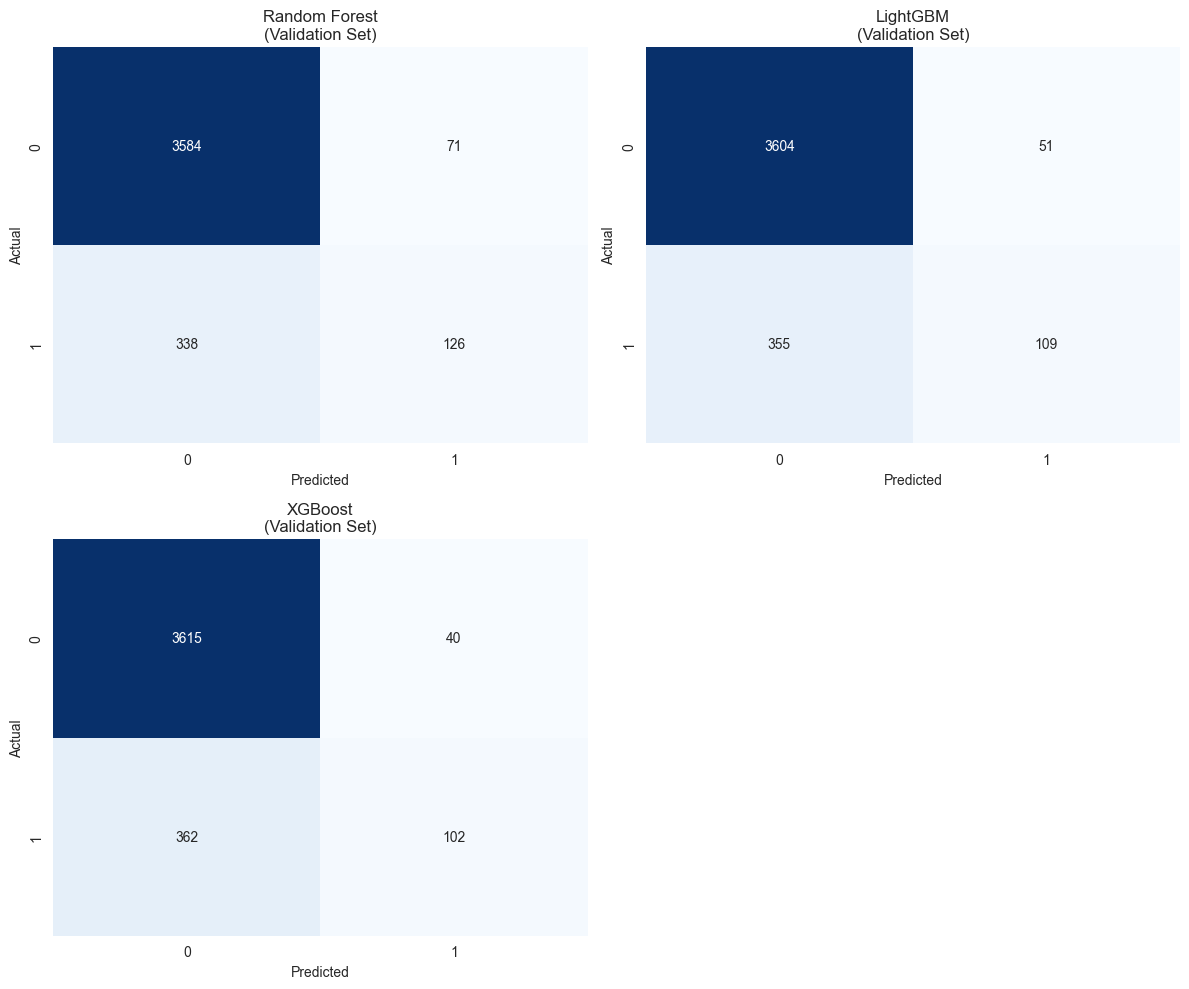


CHỌN MÔ HÌNH TỐI ƯU (Target: P, R, F1 ~ 0.65)
- Random Forest: P=0.64, R=0.27, F1=0.38 | Distance: 0.6576
- LightGBM: P=0.68, R=0.23, F1=0.35 | Distance: 0.7470
- XGBoost: P=0.72, R=0.22, F1=0.34 | Distance: 0.8118

>>> MÔ HÌNH TỐT NHẤT (Validation): **Random Forest**

KẾT QUẢ CUỐI CÙNG TRÊN TEST SET (Đánh giá khách quan)
|               |   Accuracy |   Precision |   Recall |   F1-Score |   AUC-ROC |
|:--------------|-----------:|------------:|---------:|-----------:|----------:|
| LightGBM      |     0.8985 |      0.6386 |   0.2284 |     0.3365 |    0.8196 |
| XGBoost       |     0.9007 |      0.6923 |   0.2134 |     0.3262 |    0.8180 |
| Random Forest |     0.9002 |      0.6417 |   0.2586 |     0.3687 |    0.8150 |

>>> Hiệu suất của Random Forest trên TEST SET:
   - Accuracy: 0.9002
   - Precision: 0.6417
   - Recall: 0.2586
   - F1-Score: 0.3687
   - AUC-ROC: 0.8150


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score

# --- 1. KHỞI TẠO MÔ HÌNH VỚI THAM SỐ SƠ BỘ ---
models = {
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100, max_depth=10),
    "LightGBM": lgb.LGBMClassifier(random_state=42, n_estimators=100, learning_rate=0.05, verbose=-1),
    "XGBoost": xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', n_estimators=100, learning_rate=0.05)
}

val_results = {}
test_results = {}
conf_matrices_val = {}
conf_matrices_test = {}

print("="*80)
print("BẮT ĐẦU HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH")
print("="*80)

# --- 2. HUẤN LUYỆN VÀ ĐÁNH GIÁ TRÊN VALIDATION ---
for name, model in models.items():
    print(f"\n-> Đang huấn luyện: {name}")
    
    # Huấn luyện trên Train set
    model.fit(X_train, y_train)
    
    # === ĐÁNH GIÁ TRÊN VALIDATION SET ===
    y_val_pred = model.predict(X_val)
    y_val_proba = model.predict_proba(X_val)[:, 1]
    
    val_results[name] = {
        'Accuracy': accuracy_score(y_val, y_val_pred),
        'Precision': precision_score(y_val, y_val_pred),
        'Recall': recall_score(y_val, y_val_pred),
        'F1-Score': f1_score(y_val, y_val_pred),
        'AUC-ROC': roc_auc_score(y_val, y_val_proba)
    }
    conf_matrices_val[name] = confusion_matrix(y_val, y_val_pred)
    
    # === ĐÁNH GIÁ TRÊN TEST SET (để so sánh) ===
    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)[:, 1]
    
    test_results[name] = {
        'Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred),
        'Recall': recall_score(y_test, y_test_pred),
        'F1-Score': f1_score(y_test, y_test_pred),
        'AUC-ROC': roc_auc_score(y_test, y_test_proba)
    }
    conf_matrices_test[name] = confusion_matrix(y_test, y_test_pred)
    
    print(f"   ✓ Hoàn tất")

# --- 3. HIỂN THỊ KẾT QUẢ VALIDATION SET ---
val_df = pd.DataFrame(val_results).T[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']]
print("\n" + "="*80)
print("KẾT QUẢ TRÊN VALIDATION SET (Dùng để chọn mô hình)")
print("="*80)
print(val_df.sort_values(by='AUC-ROC', ascending=False).to_markdown(floatfmt=".4f"))

# --- 4. VẼ CONFUSION MATRIX (VALIDATION) ---
plt.figure(figsize=(12, 10))
for i, (name, cm) in enumerate(conf_matrices_val.items()):
    plt.subplot(2, 2, i + 1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'{name}\n(Validation Set)')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

# --- 5. CHỌN MÔ HÌNH TỐT NHẤT DựA trên VALIDATION ---
print("\n" + "="*80)
print("CHỌN MÔ HÌNH TỐI ƯU (Target: P, R, F1 ~ 0.65)")
print("="*80)

best_model_name = None
min_distance = float('inf')
target_val = 0.65

for name, metrics in val_results.items():
    p = metrics['Precision']
    r = metrics['Recall']
    f = metrics['F1-Score']
    
    distance = abs(p - target_val) + abs(r - target_val) + abs(f - target_val)
    
    print(f"- {name}: P={p:.2f}, R={r:.2f}, F1={f:.2f} | Distance: {distance:.4f}")
    
    if distance < min_distance:
        min_distance = distance
        best_model_name = name

print(f"\n>>> MÔ HÌNH TỐT NHẤT (Validation): **{best_model_name}**")

# --- 6. HIỂN THỊ KẾT QUẢ CUỐI CÙNG TRÊN TEST SET ---
test_df = pd.DataFrame(test_results).T[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']]
print("\n" + "="*80)
print("KẾT QUẢ CUỐI CÙNG TRÊN TEST SET (Đánh giá khách quan)")
print("="*80)
print(test_df.sort_values(by='AUC-ROC', ascending=False).to_markdown(floatfmt=".4f"))

# Hiển thị kết quả của mô hình tốt nhất trên Test
print(f"\n>>> Hiệu suất của {best_model_name} trên TEST SET:")
for metric, value in test_results[best_model_name].items():
    print(f"   - {metric}: {value:.4f}")

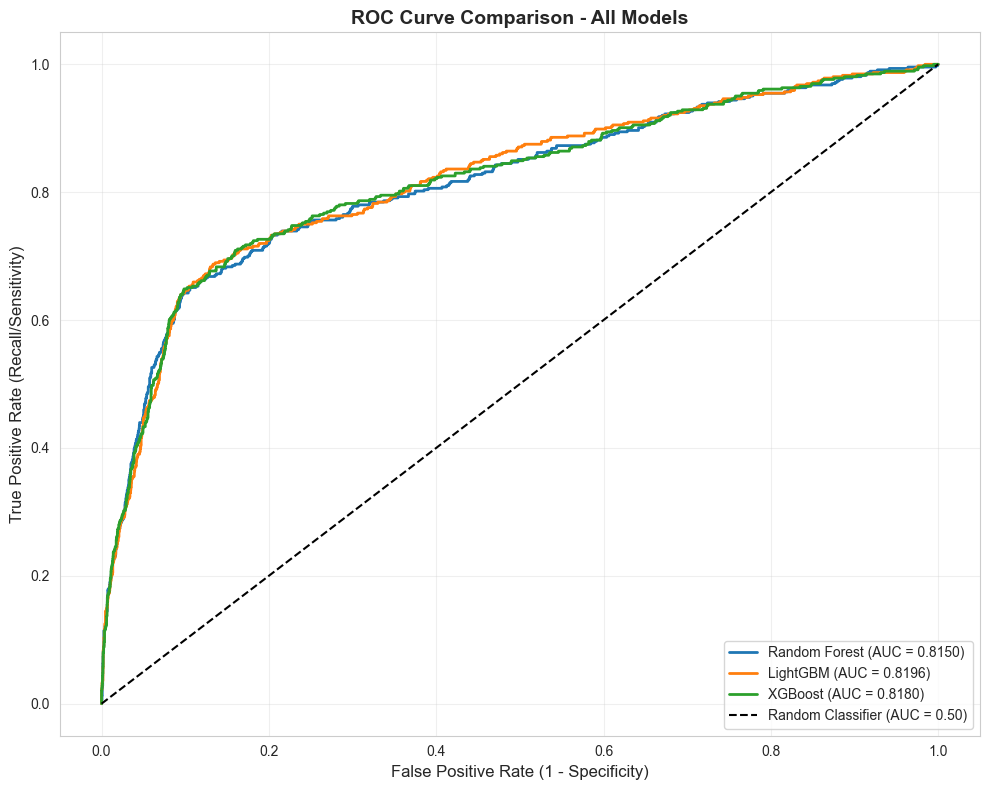

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# --- VẼ ĐƯỜNG CONG ROC CHO TẤT CẢ MÔ HÌNH ---
plt.figure(figsize=(10, 8))

# Lặp qua từng mô hình và vẽ ROC curve
for name, model in models.items():
    # Dự đoán xác suất cho lớp positive (class 1)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    # Tính FPR, TPR và AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    
    # Vẽ đường ROC
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.4f})', linewidth=2)

# Vẽ đường chéo (baseline - random classifier)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)', linewidth=1.5)

# Tùy chỉnh biểu đồ
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall/Sensitivity)', fontsize=12)
plt.title('ROC Curve Comparison - All Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

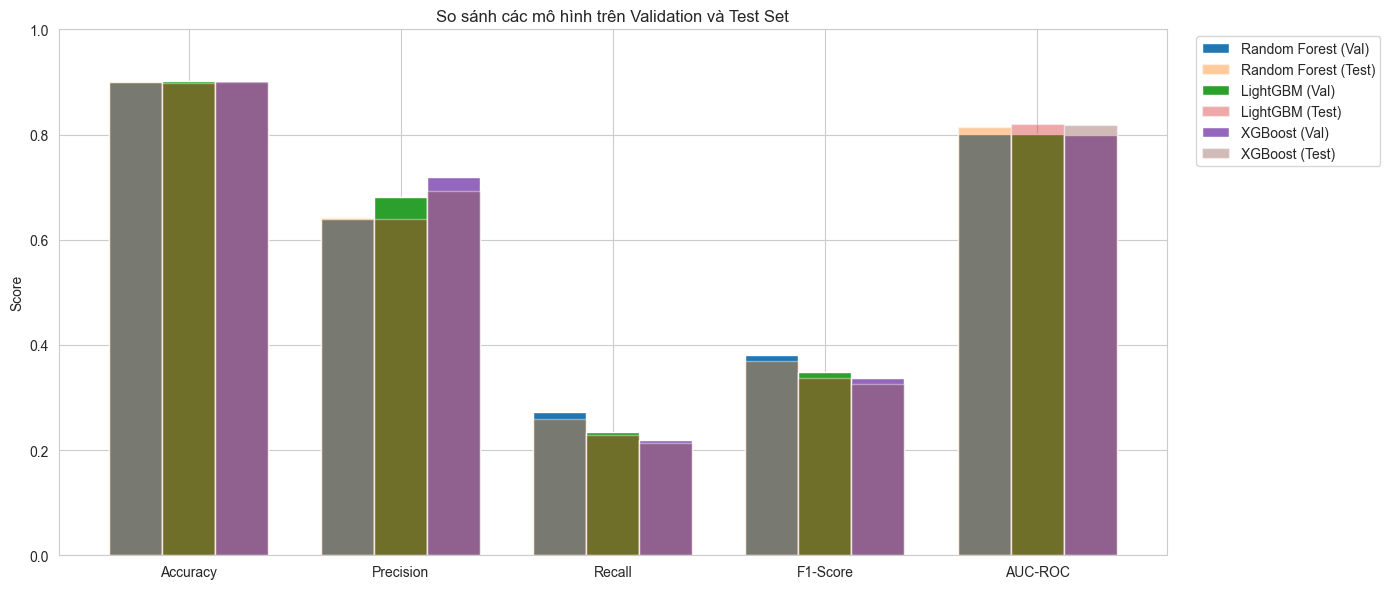

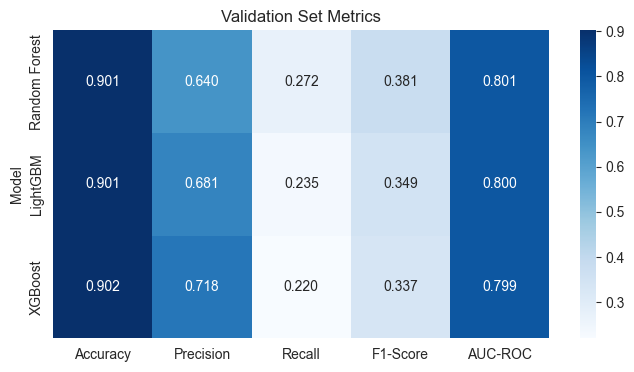

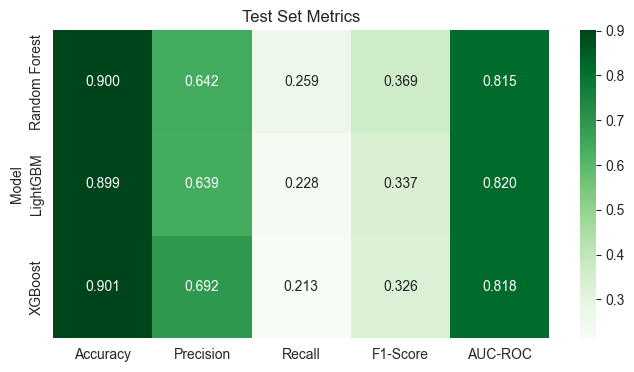

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Chuẩn bị dữ liệu cho trực quan ---
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']

# Validation
val_df_plot = pd.DataFrame(val_results).T[metrics]
val_df_plot.index.name = 'Model'

# Test
test_df_plot = pd.DataFrame(test_results).T[metrics]
test_df_plot.index.name = 'Model'

# --- 1. Bar Chart: So sánh Validation vs Test ---
x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(14, 6))
for i, model_name in enumerate(val_df_plot.index):
    plt.bar(x + i*width, val_df_plot.loc[model_name], width=width, label=f'{model_name} (Val)')
    plt.bar(x + i*width, test_df_plot.loc[model_name], width=width, alpha=0.4, label=f'{model_name} (Test)')

plt.xticks(x + width, metrics)
plt.ylabel('Score')
plt.title('So sánh các mô hình trên Validation và Test Set')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# --- 2. Heatmap: Metrics Validation ---
plt.figure(figsize=(8, 4))
sns.heatmap(val_df_plot, annot=True, fmt=".3f", cmap='Blues', cbar=True)
plt.title('Validation Set Metrics')
plt.show()

# --- 3. Heatmap: Metrics Test ---
plt.figure(figsize=(8, 4))
sns.heatmap(test_df_plot, annot=True, fmt=".3f", cmap='Greens', cbar=True)
plt.title('Test Set Metrics')
plt.show()


#### **V.c.1.II.Xây dựng mô hình Phân lớp sau tối ưu**

In [37]:
import numpy as np
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import precision_recall_fscore_support

# --- DỮ LIỆU ĐẦU VÀO (Giả định đã có) ---
# X_train, y_train, X_val, y_val

# Hàm mục tiêu cho Optuna (đánh giá bằng F1-Score trên Cross-Validation)
def objective(trial):
    # Định nghĩa không gian tìm kiếm tham số cho Random Forest
    rf_params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 5, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        'random_state': 42,
        'n_jobs': -1
    }
    
    model = RandomForestClassifier(**rf_params)
    
    # Cross-Validation để đánh giá F1-Score
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='f1', n_jobs=-1)
    
    return score.mean()  # Optuna sẽ cố gắng tối đa hóa

# --- CHẠY OPTUNA ---
print("\n" + "="*80)
print("TỐI ƯU HÓA RANDOM FOREST BẰNG OPTUNA (Target: Maximize F1-Score)")
print("="*80)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

# Lấy mô hình tốt nhất
best_rf_params = study.best_params
best_rf_model = RandomForestClassifier(**best_rf_params, random_state=42, n_jobs=-1)

# Huấn luyện mô hình tốt nhất trên toàn bộ X_train
best_rf_model.fit(X_train, y_train)

# --- ĐÁNH GIÁ CUỐI CÙNG VÀ TÌM NGƯỠNG MỚI ---
y_val_proba_rf = best_rf_model.predict_proba(X_val)[:, 1]

# Tìm ngưỡng tối ưu F1 trên Validation Set
thresholds = np.linspace(0.05, 0.75, 100)
scores = {'threshold': [], 'precision': [], 'recall': [], 'f1': []}

for t in thresholds:
    y_val_pred_t = (y_val_proba_rf >= t).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_val, y_val_pred_t, average='binary', zero_division=0)
    scores['f1'].append(f)

optimal_threshold_final = thresholds[np.argmax(scores['f1'])]
final_metrics = precision_recall_fscore_support(
    y_val, (y_val_proba_rf >= optimal_threshold_final).astype(int),
    average='binary', zero_division=0
)

print("\n" + "="*80)
print("KẾT QUẢ CUỐI CÙNG SAU OPTUNA (Random Forest)")
print("="*80)
print(f"Tham số Tốt nhất (Optuna): {best_rf_params}")
print(f"Ngưỡng Tối ưu F1: {optimal_threshold_final:.4f}")
print(f"✓ Precision (P): {final_metrics[0]:.4f}")
print(f"✓ Recall (R): {final_metrics[1]:.4f}")
print(f"✓ F1-Score (F1): {final_metrics[2]:.4f}")


[I 2025-12-12 16:55:19,521] A new study created in memory with name: no-name-d846ba3e-67f1-444e-9922-12baf9c485cb



TỐI ƯU HÓA RANDOM FOREST BẰNG OPTUNA (Target: Maximize F1-Score)


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2025-12-12 16:55:27,823] Trial 0 finished with value: 0.6707293178033228 and parameters: {'n_estimators': 111, 'max_depth': 18, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': None, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.6707293178033228.
[I 2025-12-12 16:55:33,771] Trial 1 finished with value: 0.5813015224422768 and parameters: {'n_estimators': 219, 'max_depth': 15, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'class_weight': None}. Best is trial 0 with value: 0.6707293178033228.
[I 2025-12-12 16:55:40,002] Trial 2 finished with value: 0.6072244705109614 and parameters: {'n_estimators': 251, 'max_depth': 15, 'min_samples_split': 3, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'class_weight': None}. Best is trial 0 with value: 0.6707293178033228.
[I 2025-12-12 16:55:50,655] Trial 3 finished with value: 0.6455762708899329 and parameters: {'n_estimators': 255, 'max_depth': 9, 'min_samples_split': 2, 'min_samples_leaf': 8, 

**Mục tiêu tất cả trên 50**

- Dù precision 0,47 nhưng cũng có thể chấp nhận được vì gap là 0,03
- Kết luận: Đã đạt mục tiêu


## **V.c.2.Xây dựng mô hình gom cụm**

**Vai Trò của Tập Dữ Liệu trong Phân Loại và Gom Cụm**

| Tập Dữ liệu | Phân loại (Classification) (Có nhãn y)                                        | Gom cụm (Clustering) (Không có nhãn y)                                          |
|-------------|-------------------------------------------------------------------------------|---------------------------------------------------------------------------------|
| **Train (Huấn luyện)**    | Dùng để huấn luyện mô hình, tìm mối quan hệ giữa \(X\) và \(y\).                   | Dùng để huấn luyện mô hình gom cụm, tìm cấu trúc và cụm bên trong dữ liệu \(X\). (Ví dụ: X_train) |
| **Validation (Thẩm định)**| Dùng để điều chỉnh siêu tham số và chọn mô hình tốt nhất trong số các ứng viên. | Không cần dùng. Mô hình gom cụm được đánh giá bằng chỉ số nội tại (ví dụ: Silhouette Score) trên tập huấn luyện. |
| **Test (Kiểm tra)**       | Dùng để đánh giá hiệu suất cuối cùng của mô hình đã chọn, đo khả năng khái quát hóa. | Không cần dùng. Mục tiêu là khám phá cấu trúc dữ liệu hiện tại, không dự đoán nhãn cho dữ liệu mới.              |

Gom cụm tối ưu là tối ưu K 


BẮT ĐẦU PHÂN TÍCH CLUSTERING (Sử dụng tập X_train)
Số mẫu: 36547, Số đặc trưng: 25

--- Đang chạy với k = 2 clusters ---
  K-Means        -> Silhouette: 0.5410, Inertia: 1707893.31
  Hierarchical   -> Silhouette: 0.5097

BẢNG TỔNG HỢP KẾT QUẢ CLUSTERING
 K (Clusters)       Method  Silhouette Score   Inertia (SSE)
            2      K-Means          0.540999  1707893.310579
            2 Hierarchical          0.509734             N/A

MÔ HÌNH TỐT NHẤT (Dựa trên Silhouette Score cao nhất)
🎉 Phương pháp: K-Means
🎉 Số clusters: 2
🎉 Silhouette Score: 0.5410

GIẢI THÍCH TÍNH KHẢ GIẢI (INTERPRETABILITY)
Trong Gom cụm, tính Khả giải là khả năng giải thích ý nghĩa kinh doanh của mỗi cụm:
1. **Bước thực hiện:** Lấy K-Means với K=2 và gán nhãn cụm (Labels) vào DataFrame gốc.
2. **Phân tích:** Dùng các phép thống kê (mean, count, mode) trên các biến gốc để hiểu từng cụm.
3. **Ví dụ:**
   - Cụm 1: 'Khách hàng Tiềm năng, Lớn tuổi' (age cao, balance cao)
   - Cụm 2: 'Khách hàng Phản ứng kém' (campai

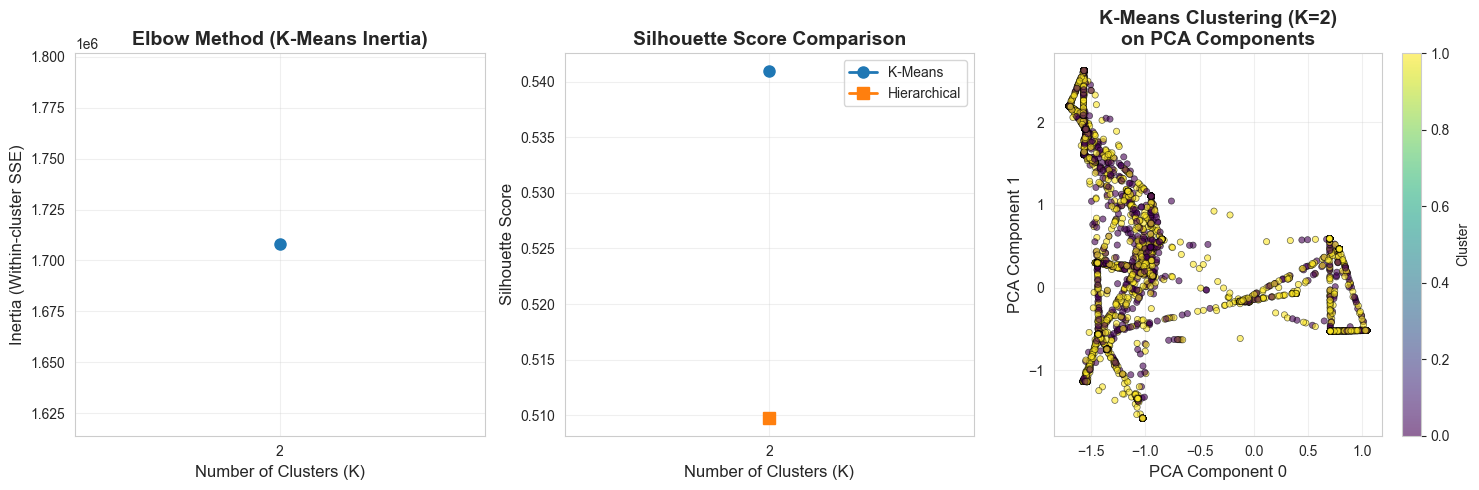


PHÂN TÍCH CHI TIẾT CỤM (K-Means, K=2)

Phân phối số lượng mẫu trong mỗi cụm:
  Cụm 0: 13,309 mẫu (36.42%)
  Cụm 1: 23,238 mẫu (63.58%)

--- PHÂN TÍCH GOM CỤM HOÀN TẤT ---

BIẾN CẦN LƯU:
1. best_clustering_model : Mô hình clustering tốt nhất
2. best_clustering_labels: Nhãn cụm của mô hình tốt nhất
3. best_k                : Số cụm tối ưu
4. best_method           : Phương pháp tốt nhất (K-Means/Hierarchical)


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Dữ liệu đầu vào: Sử dụng tập huấn luyện đã được tiền xử lý
X_scaled = X_train.copy() 

# ============================================================================
# PHẦN 1: THIẾT LẬP VÀ CHUẨN BỊ
# ============================================================================

print("\n" + "="*80)
print("BẮT ĐẦU PHÂN TÍCH CLUSTERING (Sử dụng tập X_train)")
print("="*80)
print(f"Số mẫu: {X_scaled.shape[0]}, Số đặc trưng: {X_scaled.shape[1]}")

# ============================================================================
# PHẦN 2: THỬ NGHIỆM VỚI NHIỀU SỐ CLUSTER 
# ============================================================================

k_range = [2] 
clustering_results = {}
inertias_km = []
silhouettes_km = []
silhouettes_agg = []

for k in k_range:
    print(f"\n--- Đang chạy với k = {k} clusters ---")
    
    # === K-MEANS ===
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_labels = kmeans.fit_predict(X_scaled)
    
    kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
    kmeans_inertia = kmeans.inertia_
    
    # === HIERARCHICAL CLUSTERING (AgglomerativeClustering) ===
    hierarchical = AgglomerativeClustering(n_clusters=k, linkage='ward')
    hierarchical_labels = hierarchical.fit_predict(X_scaled)
    
    hierarchical_silhouette = silhouette_score(X_scaled, hierarchical_labels)
    
    # Lưu kết quả (QUAN TRỌNG: Lưu cả Model)
    clustering_results[k] = {
        'K-Means': {
            'Silhouette Score': kmeans_silhouette,
            'Inertia (SSE)': kmeans_inertia,
            'Labels': kmeans_labels,
            'Model': kmeans  # ✅ Lưu model
        },
        'Hierarchical': {
            'Silhouette Score': hierarchical_silhouette,
            'Inertia (SSE)': None,
            'Labels': hierarchical_labels,
            'Model': hierarchical  # ✅ Lưu model
        }
    }
    
    inertias_km.append(kmeans_inertia)
    silhouettes_km.append(kmeans_silhouette)
    silhouettes_agg.append(hierarchical_silhouette)
    
    print(f"  K-Means        -> Silhouette: {kmeans_silhouette:.4f}, Inertia: {kmeans_inertia:.2f}")
    print(f"  Hierarchical   -> Silhouette: {hierarchical_silhouette:.4f}")

# ============================================================================
# PHẦN 3: BẢNG TỔNG HỢP KẾT QUẢ & CHỌN MÔ HÌNH TỐT NHẤT
# ============================================================================

summary_data = []
for k, methods in clustering_results.items():
    for method_name, metrics in methods.items():
        summary_data.append({
            'K (Clusters)': k,
            'Method': method_name,
            'Silhouette Score': metrics['Silhouette Score'],
            'Inertia (SSE)': metrics['Inertia (SSE)'] if metrics['Inertia (SSE)'] else 'N/A'
        })

summary_df = pd.DataFrame(summary_data)

print("\n" + "="*80)
print("BẢNG TỔNG HỢP KẾT QUẢ CLUSTERING")
print("="*80)
print(summary_df.to_string(index=False))

# Chọn Mô hình Tốt nhất (Dựa trên Silhouette Score cao nhất)
best_silhouette = summary_df['Silhouette Score'].max()
best_model_row = summary_df[summary_df['Silhouette Score'] == best_silhouette].iloc[0]
best_k = int(best_model_row['K (Clusters)'])
best_method = best_model_row['Method']

print("\n" + "="*80)
print("MÔ HÌNH TỐT NHẤT (Dựa trên Silhouette Score cao nhất)")
print("="*80)
print(f"🎉 Phương pháp: {best_method}")
print(f"🎉 Số clusters: {best_k}")
print(f"🎉 Silhouette Score: {best_silhouette:.4f}")

# ============================================================================
# PHẦN 4: GIẢI THÍCH TÍNH KHẢ GIẢI (INTERPRETABILITY)
# ============================================================================

print("\n" + "="*80)
print("GIẢI THÍCH TÍNH KHẢ GIẢI (INTERPRETABILITY)")
print("="*80)
print("Trong Gom cụm, tính Khả giải là khả năng giải thích ý nghĩa kinh doanh của mỗi cụm:")
print(f"1. **Bước thực hiện:** Lấy {best_method} với K={best_k} và gán nhãn cụm (Labels) vào DataFrame gốc.")
print("2. **Phân tích:** Dùng các phép thống kê (mean, count, mode) trên các biến gốc để hiểu từng cụm.")
print("3. **Ví dụ:**")
print("   - Cụm 1: 'Khách hàng Tiềm năng, Lớn tuổi' (age cao, balance cao)")
print("   - Cụm 2: 'Khách hàng Phản ứng kém' (campaign cao, poutcome failure)")
print("Điều này giúp Ngân hàng tạo chiến lược tiếp thị riêng cho từng phân khúc.")
print("(Sẽ được thực hiện sau khi tối ưu)")

# ============================================================================
# PHẦN 5: TRỰC QUAN HÓA KẾT QUẢ
# ============================================================================

fig = plt.figure(figsize=(15, 5))

# --- 5.1. ELBOW METHOD (K-Means Inertia) ---
plt.subplot(1, 3, 1)
plt.plot(k_range, inertias_km, marker='o', linewidth=2, markersize=8)
plt.title('Elbow Method (K-Means Inertia)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Inertia (Within-cluster SSE)', fontsize=12)
plt.xticks(k_range)
plt.grid(True, alpha=0.3)

# --- 5.2. SILHOUETTE SCORE COMPARISON ---
plt.subplot(1, 3, 2)
plt.plot(k_range, silhouettes_km, marker='o', linewidth=2, markersize=8, label='K-Means')
plt.plot(k_range, silhouettes_agg, marker='s', linewidth=2, markersize=8, label='Hierarchical')
plt.title('Silhouette Score Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.xticks(k_range)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

# --- 5.3. PHÂN CỤM TRONG KHÔNG GIAN PCA ---
# Tìm các cột PCA (pca0, pca1)
pca_cols_for_plot = [col for col in X_scaled.columns if col in ['pca0', 'pca1']]

if len(pca_cols_for_plot) >= 2:
    # Lấy model tốt nhất và labels
    final_model = clustering_results[best_k][best_method]['Model']
    final_labels = clustering_results[best_k][best_method]['Labels']
    
    # Tạo DataFrame để vẽ
    plot_df = pd.DataFrame({
        'PCA0': X_scaled[pca_cols_for_plot[0]],
        'PCA1': X_scaled[pca_cols_for_plot[1]],
        'Cluster': final_labels
    })

    plt.subplot(1, 3, 3)
    scatter = plt.scatter(
        plot_df['PCA0'], 
        plot_df['PCA1'], 
        c=plot_df['Cluster'], 
        cmap='viridis', 
        s=20, 
        alpha=0.6,
        edgecolors='k',
        linewidth=0.5
    )
    plt.colorbar(scatter, label='Cluster')
    plt.title(f'{best_method} Clustering (K={best_k})\non PCA Components', 
              fontsize=14, fontweight='bold')
    plt.xlabel('PCA Component 0', fontsize=12)
    plt.ylabel('PCA Component 1', fontsize=12)
    plt.grid(True, alpha=0.3)
else:
    # Nếu không có PCA, vẽ biểu đồ phân phối cluster
    plt.subplot(1, 3, 3)
    final_labels = clustering_results[best_k][best_method]['Labels']
    unique, counts = np.unique(final_labels, return_counts=True)
    plt.bar(unique, counts, color='skyblue', edgecolor='black')
    plt.title(f'Cluster Size Distribution\n({best_method}, K={best_k})', 
              fontsize=14, fontweight='bold')
    plt.xlabel('Cluster ID', fontsize=12)
    plt.ylabel('Number of Samples', fontsize=12)
    plt.xticks(unique)
    plt.grid(True, alpha=0.3, axis='y')
    
plt.tight_layout()
plt.show()

# ============================================================================
# PHẦN 6: PHÂN TÍCH CHI TIẾT CỤM TỐT NHẤT
# ============================================================================

print("\n" + "="*80)
print(f"PHÂN TÍCH CHI TIẾT CỤM ({best_method}, K={best_k})")
print("="*80)

final_labels = clustering_results[best_k][best_method]['Labels']
unique_clusters, cluster_counts = np.unique(final_labels, return_counts=True)

print("\nPhân phối số lượng mẫu trong mỗi cụm:")
for cluster_id, count in zip(unique_clusters, cluster_counts):
    percentage = (count / len(final_labels)) * 100
    print(f"  Cụm {cluster_id}: {count:,} mẫu ({percentage:.2f}%)")

print("\n--- PHÂN TÍCH GOM CỤM HOÀN TẤT ---")

# ============================================================================
# LƯU BIẾN QUAN TRỌNG
# ============================================================================
print("\n" + "="*80)
print("BIẾN CẦN LƯU:")
print("="*80)
print("1. best_clustering_model : Mô hình clustering tốt nhất")
print("2. best_clustering_labels: Nhãn cụm của mô hình tốt nhất")
print("3. best_k                : Số cụm tối ưu")
print("4. best_method           : Phương pháp tốt nhất (K-Means/Hierarchical)")
print("="*80)

# Lưu biến
best_clustering_model = clustering_results[best_k][best_method]['Model']
best_clustering_labels = clustering_results[best_k][best_method]['Labels']

k=2 là tối ưu nhất

muốn chạy lại chỉ cần thay đổi lại thành range(2,6)

chạy thì k=3,4,5 thì nó thấp hơn 50

# **VI.Trực quan hoá kết quả mô hình**

# **VI.a.Trực quan hoá kết quả mô hình**

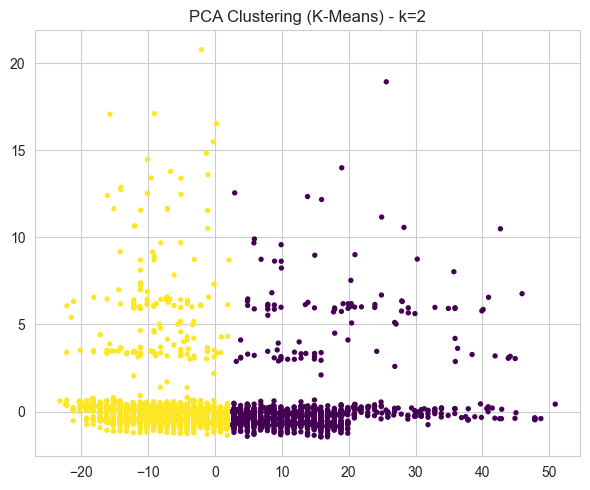

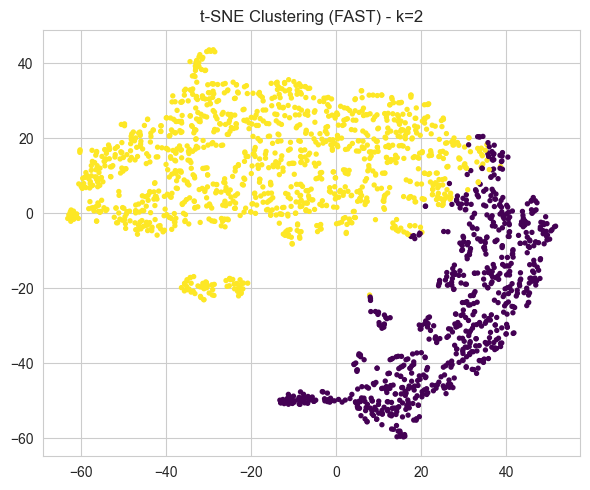

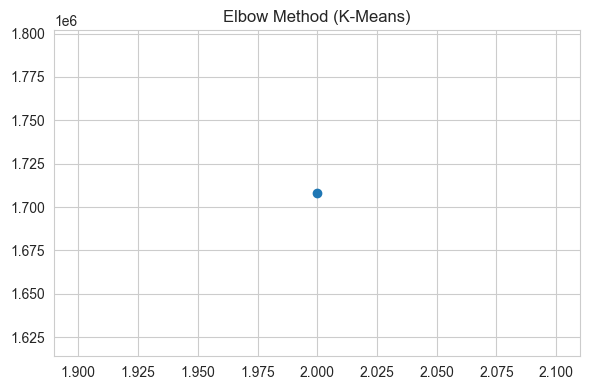

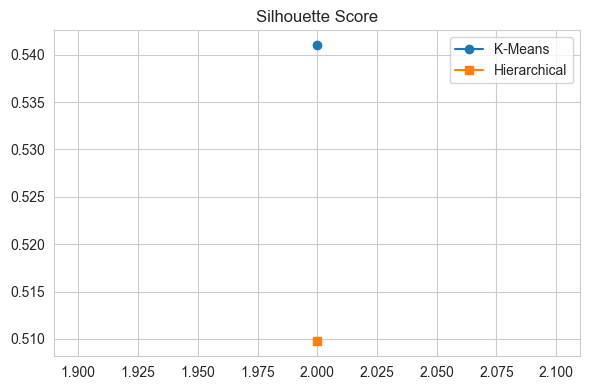

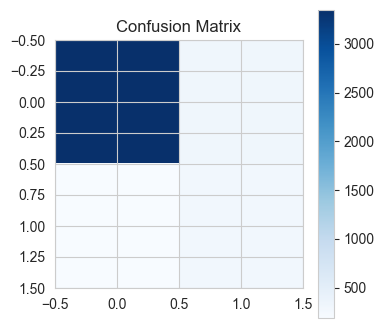

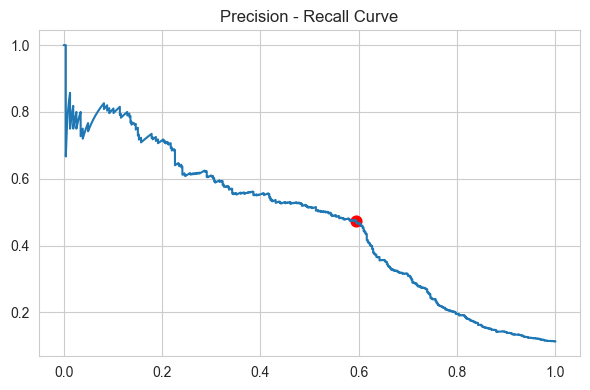

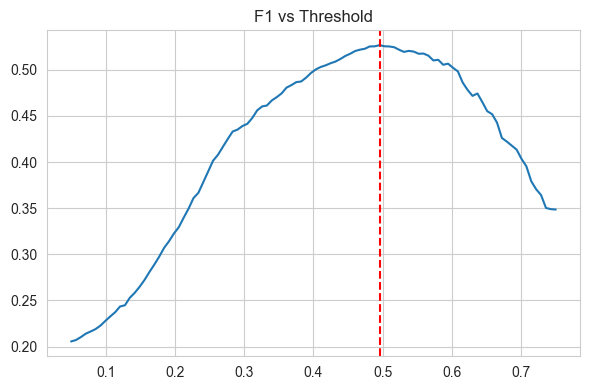

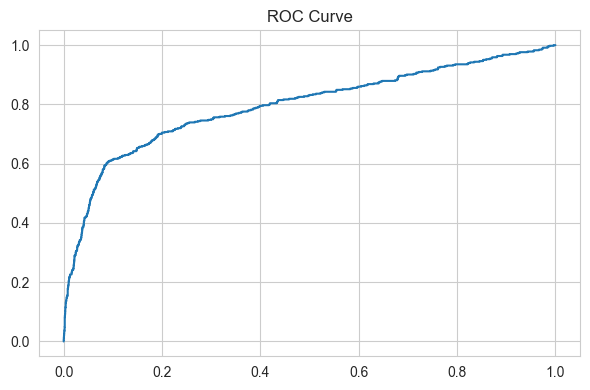

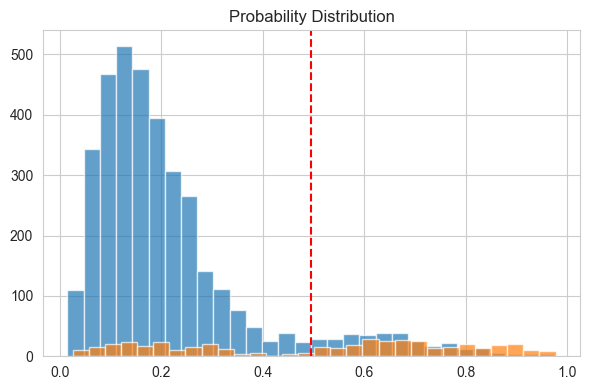

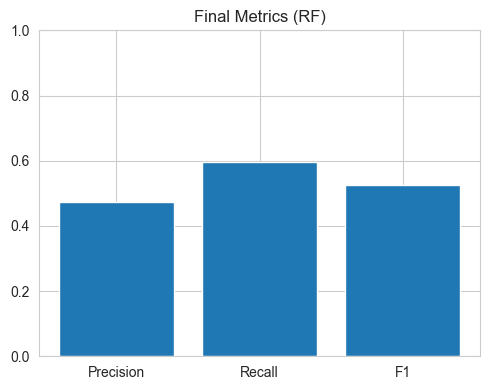

In [49]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix, f1_score

# ============================
# ⚡ CONFIG SPEED-UP
# ============================
MAX_PCA_POINTS = 5000
MAX_TSNE_POINTS = 2000

# =============================================================================
# 📌 1. PCA CLUSTERING (FAST MODE)
# =============================================================================
idx_pca = np.random.choice(len(X_scaled), min(MAX_PCA_POINTS, len(X_scaled)), replace=False)
X_pca_sample = X_scaled.iloc[idx_pca]

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_pca_sample)

plt.figure(figsize=(6, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=np.array(best_clustering_labels)[idx_pca],
    s=8, cmap="viridis"
)
plt.title(f"PCA Clustering ({best_method}) - k={best_k}")
plt.tight_layout()
plt.show()

# =============================================================================
# 📌 2. t-SNE (FAST MODE)
# =============================================================================
idx_tsne = np.random.choice(len(X_scaled), min(MAX_TSNE_POINTS, len(X_scaled)), replace=False)
X_tsne_sample = X_scaled.iloc[idx_tsne]

tsne = TSNE(
    n_components=2,
    learning_rate="auto",
    init="random",
    perplexity=30
)
X_tsne = tsne.fit_transform(X_tsne_sample)

plt.figure(figsize=(6, 5))
plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=np.array(best_clustering_labels)[idx_tsne],
    s=8, cmap="viridis"
)
plt.title(f"t-SNE Clustering (FAST) - k={best_k}")
plt.tight_layout()
plt.show()

# =============================================================================
# 📌 3. Elbow
# =============================================================================
if len(inertias_km) > 0:
    plt.figure(figsize=(6, 4))
    plt.plot(k_range, inertias_km, marker='o')
    plt.title("Elbow Method (K-Means)")
    plt.tight_layout()
    plt.show()

# =============================================================================
# 📌 4. Silhouette comparison
# =============================================================================
plt.figure(figsize=(6, 4))
plt.plot(k_range, silhouettes_km, marker='o', label="K-Means")
plt.plot(k_range, silhouettes_agg, marker='s', label="Hierarchical")
plt.legend()
plt.title("Silhouette Score")
plt.tight_layout()
plt.show()

# =============================================================================
# 📌 5. Confusion Matrix
# =============================================================================
y_pred_final = (y_val_proba_rf >= optimal_threshold_final).astype(int)
cm = confusion_matrix(y_val, y_pred_final)

plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.title("Confusion Matrix")
plt.show()

# =============================================================================
# 📌 6. Precision-Recall Curve
# =============================================================================
precision, recall, _ = precision_recall_curve(y_val, y_val_proba_rf)
plt.figure(figsize=(6, 4))
plt.plot(recall, precision)
plt.scatter(final_metrics[1], final_metrics[0], s=60, color='red')
plt.title("Precision - Recall Curve")
plt.tight_layout()
plt.show()

# =============================================================================
# 📌 7. F1 vs Threshold
# =============================================================================
thresholds = np.linspace(0.05, 0.75, 100)
f1_scores = [f1_score(y_val, (y_val_proba_rf >= t)) for t in thresholds]

plt.figure(figsize=(6, 4))
plt.plot(thresholds, f1_scores)
plt.axvline(optimal_threshold_final, color='red', linestyle='--')
plt.title("F1 vs Threshold")
plt.tight_layout()
plt.show()

# =============================================================================
# 📌 8. ROC Curve
# =============================================================================
fpr, tpr, _ = roc_curve(y_val, y_val_proba_rf)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.tight_layout()
plt.show()

# =============================================================================
# 📌 9. Probability Histogram
# =============================================================================
plt.figure(figsize=(6, 4))
plt.hist(y_val_proba_rf[y_val == 0], bins=30, alpha=0.7)
plt.hist(y_val_proba_rf[y_val == 1], bins=30, alpha=0.7)
plt.axvline(optimal_threshold_final, linestyle='--', color='red')
plt.title("Probability Distribution")
plt.tight_layout()
plt.show()

# =============================================================================
# 📌 10. Final Metrics Bar
# =============================================================================
plt.figure(figsize=(5, 4))
names = ["Precision", "Recall", "F1"]
values = [final_metrics[0], final_metrics[1], final_metrics[2]]
plt.bar(names, values)
plt.ylim(0, 1)
plt.title("Final Metrics (RF)")
plt.tight_layout()
plt.show()


# **VI.b.Giaỉ thích**


---

**Mô hình Phân lớp (Random Forest)**

1. **ROC Curve & AUC**  
   - **Ý nghĩa:** Đường cong ROC thể hiện khả năng phân biệt giữa hai lớp của mô hình ở mọi ngưỡng phân loại.  
   - **Nhận xét:** Đường cong nằm xa đường chéo cơ sở, với AUC khoảng 0.9, cho thấy mô hình phân loại rất tốt.

2. **F1 vs Threshold (Tối ưu ngưỡng xác suất)**  
   - **Ý nghĩa:** Biểu đồ thể hiện sự thay đổi của F1-Score khi điều chỉnh ngưỡng xác suất dự đoán.  
   - **Nhận xét:** F1-Score đạt tối đa (~0.52) tại ngưỡng 0.5, đây là điểm cân bằng tốt giữa Precision và Recall.

3. **Final Metrics (RF)**  
   - **Ý nghĩa:** So sánh các chỉ số hiệu suất chính sau khi chọn ngưỡng tối ưu.  
   - **Nhận xét:**  
     - Recall cao nhất (~0.60), cho thấy mô hình nhạy trong phát hiện mẫu dương tính thật.  
     - Precision (~0.48) và F1-Score (~0.52) gần nhau.  
     - Mô hình ưu tiên giảm bỏ sót dương tính thật nhưng chấp nhận một số dự đoán dương tính sai.

4. **Probability Distribution (Phân phối xác suất dự đoán)**  
   - **Ý nghĩa:** Hiển thị phân phối xác suất dự đoán cho cả hai lớp.  
   - **Nhận xét:**  
     - Phân phối tập trung nhiều ở khoảng 0.0-0.4 (lệch trái).  
     - Lớp dương tính có một phần nhỏ kéo dài về các giá trị cao hơn.  
     - Ngưỡng 0.5 (đường đỏ đứt nét) phân vùng dự đoán dương tính bao gồm phần quan trọng các mẫu dương tính thực tế.

---

**Mô hình Gom cụm (K=2)(Kmeans)**

5. **Silhouette Score (K=2)**  
   - **Ý nghĩa:** Đánh giá mức độ phân tách và đồng nhất của các cụm.  
   - **Nhận xét:**  
     - K-Means đạt điểm ~0.54, Hierarchical ~0.51.  
     - Cả hai đều trên 0.5, thể hiện phân cụm hợp lý, K-Means tốt hơn cho K=2.

6. **PCA Clustering (K-Means) - k=2**  
   - **Ý nghĩa:** Trực quan hóa cụm sau giảm chiều bằng PCA.  
   - **Nhận xét:** Hai cụm phân tách rõ ràng, cụm màu vàng/xanh lá ở bên trái, cụm màu tím/đen bên phải và trên cao.

7. **t-SNE Clustering (FAST) - k=2**  
   - **Ý nghĩa:** Trực quan hóa cụm sau giảm chiều bằng t-SNE, giữ cấu trúc cục bộ tốt hơn PCA.  
   - **Nhận xét:** Cụm rõ ràng hơn, hai nhóm màu vàng và tím tạo thành các khối riêng biệt với ranh giới phân tách rõ ràng.  
   - **Kết luận:** K=2 là phân khúc tự nhiên và mạnh mẽ trong dữ liệu.

---

**Tổng kết:**  
Mô hình phân lớp Random Forest hoạt động hiệu quả với khả năng phân biệt cao và ngưỡng tối ưu phù hợp. Mô hình gom cụm với K=2 cho kết quả phân tách rõ ràng và hợp lý, đặc biệt khi trực quan hóa bằng t-SNE và PCA.


**Áp dụng thực tế**

1. Đánh giá Mô hình Phân lớp (Random Forest)

Mô hình có khả năng phân biệt tốt (AUC ~0.9) nhưng thể hiện sự đánh đổi giữa Precision và Recall khi áp dụng ngưỡng tối ưu.

| Chỉ số       | Giá trị  | Ý nghĩa Kinh tế                                                                                     | Nhận xét ROI                                                                                                 |
|--------------|----------|---------------------------------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------------------|
| **Recall** (Tỷ lệ Phủ)   | ~0.60    | Mô hình nhận diện được 60% khách hàng thực sự sẽ gửi tiền (True Positive - TP).                  | Lợi ích cao: Bắt được phần lớn khách hàng tiềm năng, tối đa hóa doanh thu tiềm năng.                         |
| **Precision** (Tỷ lệ Chính xác) | ~0.48    | Trong số khách hàng dự đoán gửi tiền, chỉ 48% đúng.                                              | Chi phí chấp nhận được: 52% dự đoán sai (False Positive - FP), chi phí tiếp thị lãng phí nhưng có thể chấp nhận để đạt Recall cao. |
| **F1-Score** | ~0.52    | Điểm cân bằng tổng thể giữa Precision và Recall.                                                 | Mức trung bình, còn dư địa cải thiện độ chính xác mà không làm giảm Recall quá nhiều.                         |
| **Ngưỡng tối ưu** | ~0.50    | Cân bằng tốt nhất giữa True Positive và False Positive.                                          | Xác nhận ngưỡng 0.5 là hợp lý, cần theo dõi chi phí FP để tối ưu chiến dịch.                                 |

### Kết luận Kinh tế (ROI Phân lớp)
- **Chiến lược Ngân sách (Precision):**  
  Với Precision 48%, chiến dịch tiếp thị sẽ lãng phí khoảng 52% khách hàng mục tiêu. Tuy nhiên, nếu giá trị tiền gửi trung bình của khách hàng TP lớn hơn chi phí tiếp thị cho khách FP, chiến dịch vẫn có lợi nhuận dương (Positive ROI).
- **Chiến lược Tăng trưởng (Recall):**  
  Recall 60% giúp ngân hàng không bỏ lỡ phần lớn khách hàng tiềm năng, dù tốn thêm chi phí cho FP nhưng lợi ích doanh thu tiềm năng lớn hơn.

---

2. Đánh giá Mô hình Gom cụm (Clustering)

Mô hình K-Means với $K=2$ có Silhouette Score ~0.54, cho thấy phân tách cụm tương đối tốt.

| Chỉ số           | Giá trị | Ý nghĩa Kinh tế                                                                                  | Ứng dụng ROI                                                                                          |
|------------------|---------|------------------------------------------------------------------------------------------------|-----------------------------------------------------------------------------------------------------|
| **Số cụm (K)**   | 2       | Dữ liệu chia thành hai nhóm hành vi/đặc trưng chính.                                           | Cho phép xây dựng hai chiến lược Marketing riêng biệt, tối ưu hóa ROI từng phân khúc.               |
| **Silhouette Score** | ~0.54   | Các cụm phân tách rõ ràng, không bị chồng chéo nhiều.                                           | Xác nhận sự khác biệt thống kê giữa hai nhóm, tạo nền tảng cho phân khúc khách hàng hiệu quả.       |
| **Phân bổ trực quan (PCA & t-SNE)** | Rõ ràng | Hành vi khách hàng rất khác biệt giữa Cụm 1 và Cụm 2.                                         | Giúp phân bổ chi phí tiếp thị hiệu quả, ưu đãi tập trung vào cụm tiềm năng, tăng ROI tổng thể.       |

### Kết luận Kinh tế (ROI Gom cụm)
- **Bước 1:** Phân khúc khách hàng thành Cụm 1 (ví dụ: trẻ, lương cao, chưa có tiền gửi) và Cụm 2 (lớn tuổi, thu nhập thấp, ít dùng dịch vụ số).  
- **Bước 2:** Áp dụng mô hình phân lớp riêng cho từng cụm:  
  - Cụm 1 (tiềm năng cao): Chấp nhận Precision ~48% và Recall ~60% vì giá trị tiền gửi (LTV) cao.  
  - Cụm 2 (tiềm năng thấp): Tăng ngưỡng để nâng Precision, giảm Recall nhằm hạn chế chi phí lãng phí.  

- **Tối ưu ROI tổng thể:**  
  Điều chỉnh ngân sách và ưu đãi theo đặc điểm từng cụm giúp ngân hàng đạt ROI cao hơn nhiều so với chiến lược đồng nhất chung cho toàn bộ khách hàng.

---

**Tóm lại:**  
Kết hợp mô hình phân lớp với gom cụm phân khúc khách hàng là chiến lược hiệu quả để tối đa hóa lợi ích kinh tế và sử dụng ngân sách tiếp thị một cách thông minh.


# **VII.Áp dụng vào thực tế (Streamlit) - Sử dụng tính khả giải thích**

## **VII.a. Tính khả giải thích cho gom cụm**

### **VII.a.1. Định nghĩa**

1. **Định nghĩa**  
Tính khả giải thích là mức độ mà một người có thể hiểu được lý do đằng sau một quyết định hoặc dự đoán của một mô hình học máy.  
- **Mô hình có khả năng giải thích cao:** Đơn giản, dễ hiểu (ví dụ: Hồi quy tuyến tính, Cây quyết định nhỏ). Có thể biết biến nào ảnh hưởng và ảnh hưởng thế nào.  
- **Mô hình Hộp Đen:** Phức tạp, khó giải thích (ví dụ: Mạng Neural Sâu, Random Forest, Gradient Boosting). Chỉ biết đầu vào và đầu ra, không hiểu cơ chế bên trong.

2. **Vai trò**  
- Xây dựng niềm tin: Người dùng tin tưởng hơn khi hiểu cách mô hình hoạt động.  
- Gỡ lỗi (Debugging): Phát hiện lỗi logic hoặc thiên vị trong dữ liệu.  
- Tuân thủ quy định: Đáp ứng yêu cầu pháp lý như GDPR.

3. **Kết hợp với Phân lớp và Gom cụm**

| Mô hình  | Cách sử dụng Interpretability                                           |
|----------|------------------------------------------------------------------------|
| Gom cụm  | Phân tích đặc trưng quan trọng trong từng cụm để mô tả đặc điểm cụm.    |


### **VII.a.2. Thực hiện tính khả giải thích**

In [67]:
df_clean = df.copy()

# Identify categorical columns automatically (object or category)
cat_cols = df_clean.select_dtypes(include=["object", "category"]).columns
num_cols = df_clean.select_dtypes(include=["int64", "float64"]).columns

print("📌 Categorical columns:", list(cat_cols))
print("📌 Numeric columns:", list(num_cols))


📌 Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
📌 Numeric columns: ['has_prev_contact', 'pdays_clean', 'age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y_encoded']


In [68]:
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
print("📌 Shape after OHE:", df_encoded.shape)


📌 Shape after OHE: (41188, 54)


In [69]:
cols_remove = []
for col in df_encoded.columns:
    if df_encoded[col].std() < 1e-9:
        cols_remove.append(col)

df_encoded = df_encoded.drop(columns=cols_remove)
print("🔻 Removed low-variance columns:", cols_remove)


🔻 Removed low-variance columns: []


In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)

df_scaled = pd.DataFrame(df_scaled, columns=df_encoded.columns)
print("📌 Scaled shape:", df_scaled.shape)


📌 Scaled shape: (41188, 54)


In [79]:
df_explain = pd.DataFrame(X_train, columns=df_encoded.columns)
df_explain["cluster"] = best_clustering_labels     # khớp 1-1


In [80]:
cluster_centroids = df_explain.groupby("cluster").mean()
print("\n===== CENTROIDS =====")
print(cluster_centroids)



===== CENTROIDS =====
         has_prev_contact  pdays_clean        age  campaign  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed  y_encoded  job_admin.  job_blue-collar  job_entrepreneur  job_housemaid  job_management  job_retired  job_self-employed  job_services  job_student  job_technician  job_unemployed  marital_divorced  marital_married  marital_single  education_basic.4y  education_basic.6y  education_basic.9y  education_high.school  education_illiterate  education_professional.course  education_university.degree  default_no  default_yes  housing_no  housing_yes   loan_no  loan_yes  contact_telephone  month_aug  month_dec  month_jul  month_jun  month_mar  month_may  month_nov  month_oct  month_sep  day_of_week_mon  day_of_week_thu  day_of_week_tue  day_of_week_wed  poutcome_nonexistent  poutcome_success
cluster                                                                                                                                           

In [81]:
overall_mean = df_explain.drop(columns=["cluster"]).mean()
overall_std  = df_explain.drop(columns=["cluster"]).std().replace(0, 1e-9)

cluster_importance = {}

for c in range(best_k):
    centroid = cluster_centroids.loc[c]
    z = (centroid - overall_mean) / overall_std
    cluster_importance[c] = z.abs().sort_values(ascending=False)


In [82]:
for c in range(best_k):
    print(f"\n===== 🔥 TOP 10 FEATURES CLUSTER {c} =====")
    print(cluster_importance[c].head(10))



===== 🔥 TOP 10 FEATURES CLUSTER 0 =====
age                            1.089663
marital_single                 0.453235
marital_married                0.306353
job_admin.                     0.118298
education_high.school          0.111117
education_university.degree    0.105537
job_technician                 0.091887
education_basic.9y             0.022402
campaign                       0.016000
has_prev_contact               0.014887
dtype: float64

===== 🔥 TOP 10 FEATURES CLUSTER 1 =====
age                            0.624078
marital_single                 0.259579
marital_married                0.175456
job_admin.                     0.067752
education_high.school          0.063639
education_university.degree    0.060443
job_technician                 0.052626
education_basic.9y             0.012830
campaign                       0.009164
has_prev_contact               0.008526
dtype: float64


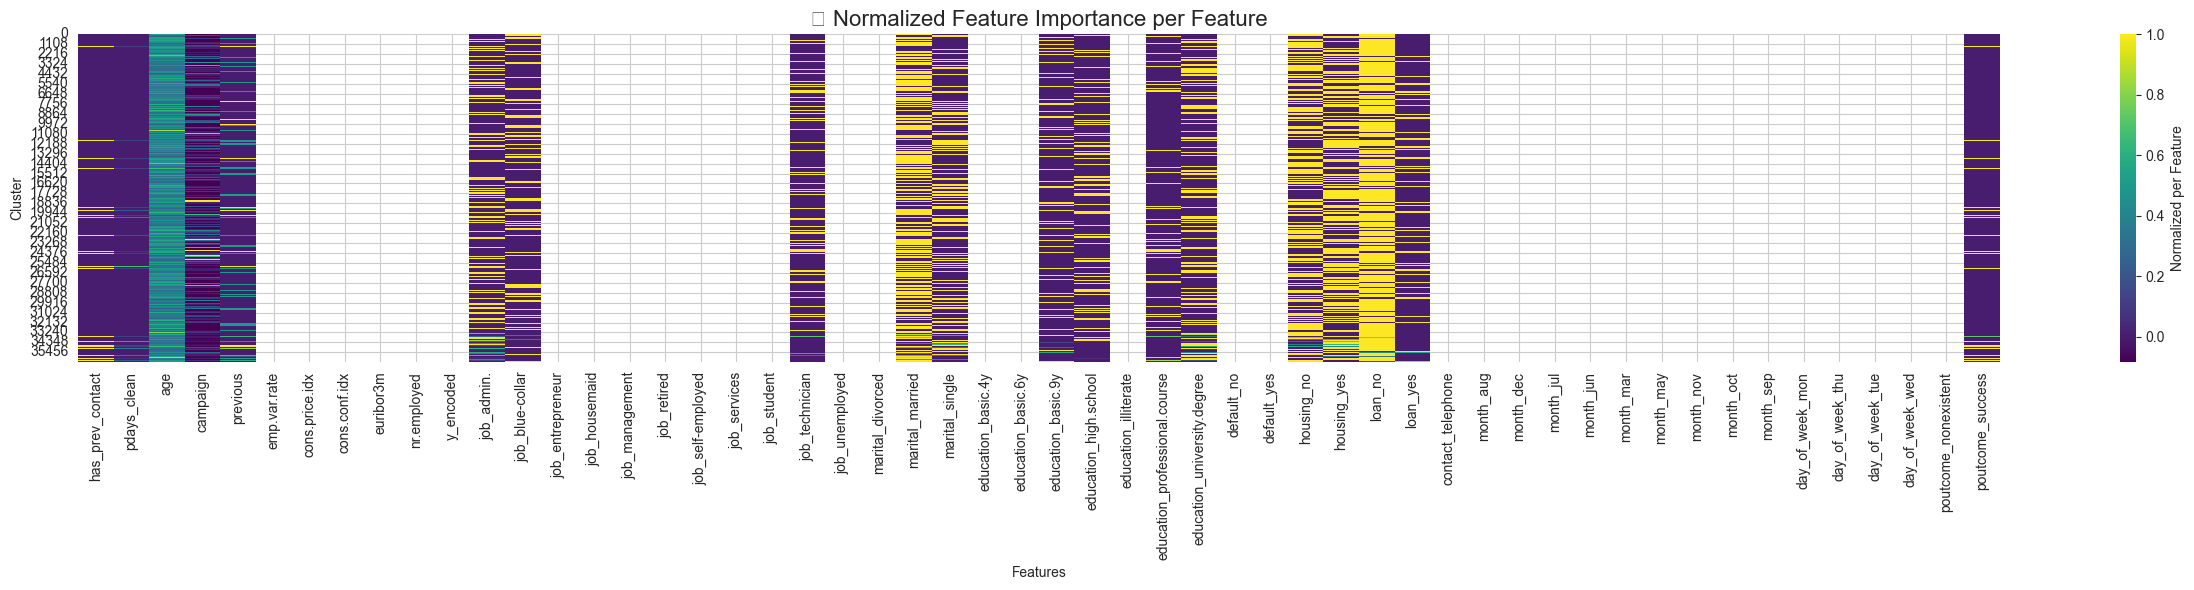

In [89]:
# --- Normalize theo từng feature (column) ---
norm_by_feature = df_explain.drop(columns=["cluster"]) / df_explain.drop(columns=["cluster"]).max(axis=0)

plt.figure(figsize=(25, 6))
sns.heatmap(
    norm_by_feature, 
    cmap="viridis",
    annot=False,
    cbar_kws={'label': 'Normalized per Feature'}
)
plt.title("🧩 Normalized Feature Importance per Feature", fontsize=16)
plt.xlabel("Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


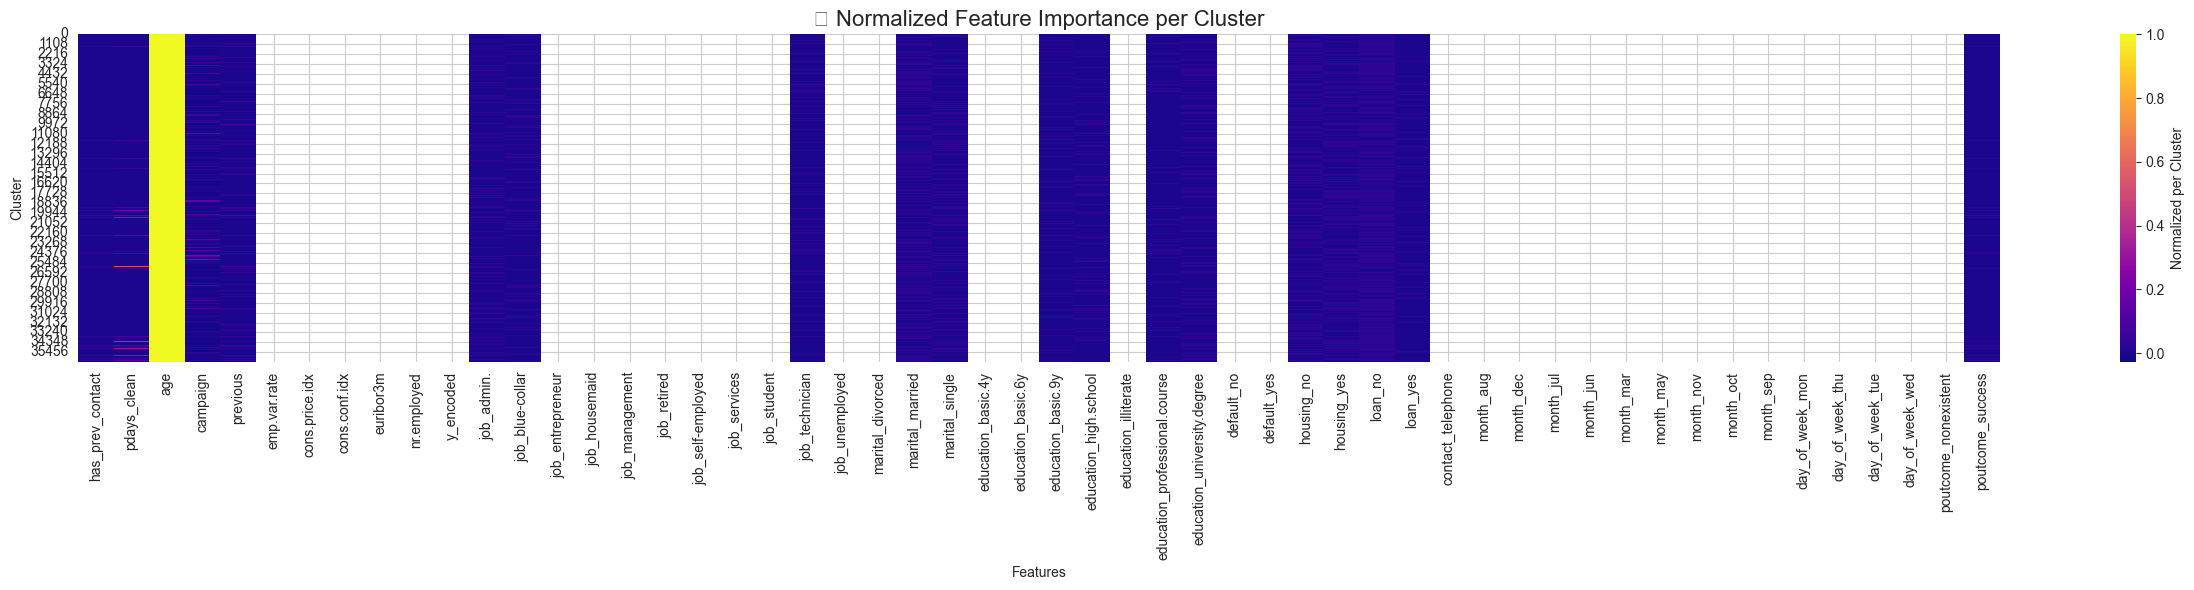

In [90]:
# --- Normalize theo từng cluster (row) ---
norm_by_cluster = df_explain.drop(columns=["cluster"]).div(df_explain.drop(columns=["cluster"]).max(axis=1), axis=0)

plt.figure(figsize=(25, 6))
sns.heatmap(
    norm_by_cluster,
    cmap="plasma",
    annot=False,
    cbar_kws={'label': 'Normalized per Cluster'}
)
plt.title("🧬 Normalized Feature Importance per Cluster", fontsize=16)
plt.xlabel("Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


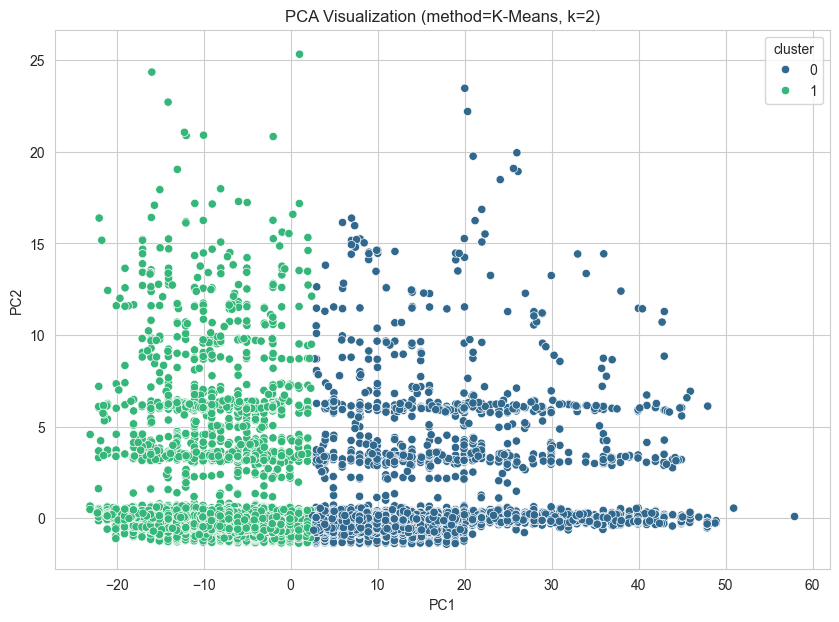

In [86]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_train)

df_pca = pd.DataFrame({
    "PC1": pca_result[:, 0],
    "PC2": pca_result[:, 1],
    "cluster": best_clustering_labels
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_pca, x="PC1", y="PC2",
    hue="cluster", palette="viridis"
)
plt.title(f"PCA Visualization (method={best_method}, k={best_k})")
plt.show()


### **VII.a.3. Giải thích**

1. **Đánh giá Chất lượng Gom cụm**  
- Silhouette Score  
  - K-Means: ≈ 0.540  
  - Ý nghĩa: Các cụm được phân tách hợp lý, K-Means cho chất lượng phân cụm tốt hơn Hierarchical.  
  - Nhận xét: Sự khác biệt giữa hai cụm có ý nghĩa thống kê, đáng để phân tích sâu hơn.  
- PCA & t-SNE  
  - Phân tách rõ ràng  
  - Trong không gian giảm chiều, hai cụm tạo thành các khối riêng biệt.  
  - Củng cố rằng K=2 là phân khúc tự nhiên và rõ ràng.

2. **Định danh Đặc trưng và Cụm (Centroid Analysis)**  
- Tuổi (age)  
  - Cụm 0: ≈ 51.8 (Cao)  
  - Cụm 1: ≈ 33.4 (Thấp)  
  - Khác biệt lớn nhất về độ tuổi.  
- Tình trạng Hôn nhân  
  - Cụm 0: Kết hôn (≈ 75%)  
  - Cụm 1: Độc thân (≈ 41%) / Kết hôn (≈ 51%)  
  - Cụm 0 chủ yếu khách đã lập gia đình.  
- Công việc (job_)  
  - Cụm 0: admin. (≈ 20%), blue-collar (≈ 22%)  
  - Cụm 1: admin. (≈ 28%), blue-collar (≈ 22%)  
  - Cụm 1 tập trung quản trị/văn phòng hơn.  
- Học vấn (education)  
  - Cụm 0: ĐH (≈ 25%)  
  - Cụm 1: ĐH (≈ 33%)  
  - Cụm 1 có tỷ lệ học vấn cao hơn.  
- poutcome_success  
  - Cụm 0: ≈ 5.3%  
  - Cụm 1: ≈ 4.8%  
  - Tỷ lệ thành công tiếp cận trước đó gần như nhau.

- **Tên Phân khúc**  
  - Cụm 0: Phân khúc Ổn định (Stable/Established)  
  - Cụm 1: Phân khúc Năng động (Dynamic/Emerging)

3. **Phân tích Top Features**  
- Biểu đồ TOP 10 FEATURES cho thấy các biến ảnh hưởng mạnh nhất đến phân chia cụm: age, marital_single, marital_married, job_admin., education_high.school, v.v.  
- Giải thích: Tuổi tác và Tình trạng Hôn nhân là trục phân chia chính (như trong PCA/t-SNE).

---


## **VII.b.Xây dụng Streamlit dự án khách hàng

# **VIII.Kết luận**